# QC0426 / VTI — Measurement

**QC0426** (trilayer graphene, stacking under investigation) on the
**VTI** rig.

`metadata.hera.policy` — scientific record: append new cells; never edit or
delete executed ones. (Who *executes* a measure cell is set by the session
mode — see the brief.)

Confirm each `# <-- verify` line at bring-up. Cells marked **PATTERN** /
**PROPOSAL** contain `<PLACEHOLDER>` values or pending decisions — review
before running.

## Setup

In [1]:
import os
import time

import numpy as np
import scipy.constants as cst

import qcodes
from qcodes import validators
from qcodes.instrument_drivers.stanford_research import SR830
from qcodes.instrument_drivers.tektronix.Keithley_2400 import Keithley_2400

import sweep

from drivers.FastBi1K5 import FastBi1K5
from drivers.Lakeshore_335 import Lakeshore_335
from drivers.SRS_DC205 import SRS_DC205
from drivers.async_station import async_station

In [2]:
main_dir = os.getcwd()
sweep.set_basedir(os.path.join(main_dir, "data"))
main_dir

'C:\\Users\\DGG\\VTI_local_data\\zack\\20260616-QC0426'

# Connect Instruments

## Magnet

In [3]:
magnet = FastBi1K5('magnet', '192.168.0.10')  # <-- verify address
magnet.status()

Connected to: Fast-Bi-1K5 Magnet Controller
---------- Magnet Status ----------
Field:               : 0.002 Tesla
Current:             : 0.018 A
Voltage:             : 0.000 V
Output Enabled       : True
Persistent Switch On : True
Loop Mode            : CC
Update Mode          : NORMAL
-----------------------------------


## Lakeshore

In [4]:
heater = Lakeshore_335('l335_3', 'GPIB0::10::INSTR')  # <-- verify address
print(heater.sample_temperature())
print(heater.vaporizer_temperature())

Connected to: LSCI 335 (serial:LSA2FM7/#######, firmware:1.4) in 0.43s
1.163
0.0


## Lock-ins

In [5]:
sr0 = SR830('sr0', "GPIB0::17::INSTR")  # <-- verify — current channel (Ithaco preamp output)
sr1 = SR830('sr1', "GPIB0::14::INSTR")  # <-- verify — also the AC drive source
sr2 = SR830('sr2', "GPIB0::19::INSTR")  # <-- verify
sr3 = SR830('sr3', "GPIB0::18::INSTR")  # <-- verify

Connected to: Stanford_Research_Systems SR830 (serial:s/n45620, firmware:ver1.07) in 0.09s
Connected to: Stanford_Research_Systems SR830 (serial:s/n83412, firmware:ver1.07) in 0.07s


C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr0 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr0 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr1 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.p

Connected to: Stanford_Research_Systems SR830 (serial:s/n41639, firmware:ver1.07) in 0.08s
Connected to: Stanford_Research_Systems SR830 (serial:s/n93552, firmware:ver1.07) in 0.07s


C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr3 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr3 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(


## Keithleys

In [6]:
k_bg = Keithley_2400('k_bg', 'GPIB0::24::INSTR')  # <-- verify address — back gate
k_bg.mode.set('VOLT')
k_bg.volt.set(0)
k_bg.rangei.set(1e-6)
k_bg.rangev.set(21)
k_bg.volt.step = 0.005

Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:0734554, firmware:C17   Jul 16 1999 15:20:40/A02  /G/F) in 0.03s


In [7]:
k_2410 = Keithley_2400('k_2410', 'GPIB0::25::INSTR')  # <-- verify address — Si global gate
k_2410.mode.set('VOLT')
k_2410.volt.set(0)
k_2410.rangei.set(1e-6)
k_2410.rangev.set(21)
k_2410.volt.step = 0.005

Connected to: KEITHLEY INSTRUMENTS INC. 2410 (serial:1293333, firmware:C30   Mar 17 2006 09:29:29/A02  /J/J) in 0.03s


## DC205 (top gate)

In [8]:
k_tg = SRS_DC205("k_tg", "ASRL7::INSTR")  # <-- verify address — top gate
k_tg.ramp_rate = 2  # V/s

Connected to: Stanford_Research_Systems DC205 (serial:s/n20500514, firmware:ver1.80) in 0.02s


In [9]:
# Sweepable top-gate parameter — appears in the data as column 'DC_bias'.
def dcbias(vg):
    k_tg.ramp_voltage(vg)

dc205_volt = qcodes.Parameter('DC_bias', unit='V', set_cmd=dcbias)

# SAFETIES

Run immediately after instrument bring-up, before any sweep.

In [10]:
# Gate validators — QC0426 GATE OPERATING LIMITS (see device card).
# Provided operating limits, not range-found this session (range-finding
# is blocklisted — see the brief). Commit exactly the device-card numbers.
TG_MIN, TG_MAX = -6.0, +7.0   # top gate (dc205_volt / k_tg), V — provided
BG_MIN, BG_MAX = -4.5, +4.5   # back gate (k_bg), V — provided
SI_MIN, SI_MAX = -50.0, +50.0  # Si gate (k_2410), V — provided
dc205_volt.vals = validators.Numbers(TG_MIN, TG_MAX)
# Instrument-level TG limit: direct k_tg.voltage()/ramp_voltage() calls
# bypass the dc205_volt wrapper; ramp steps also go through k_tg.voltage.
k_tg.voltage.vals = validators.Numbers(TG_MIN, TG_MAX)
k_bg.volt.vals = validators.Numbers(BG_MIN, BG_MAX)
k_2410.volt.vals = validators.Numbers(SI_MIN, SI_MAX)

# Limit lists for sanitize_tg_bg()
tg_lims, bg_lims = [TG_MIN, TG_MAX], [BG_MIN, BG_MAX]

# Session field cap — machine-enforced: magnet.mag is a qcodes Parameter,
# so this validator rejects any magnet.mag(target) with |B| > B_SESSION_CAP
# before any hardware traffic. (Driver max_field_T = 14.0 remains as backstop.)
B_SESSION_CAP = 8.0  # Tesla
magnet.mag.vals = validators.Numbers(-B_SESSION_CAP, B_SESSION_CAP)

# Temperature setpoint cap — TYPO GUARD ONLY (sample_setpoint(3000) vs 300).
# The real safe T/B envelope is a rig-card item, unestablished this session.
T_SESSION_CAP = 310.0  # K  # <-- verify
heater.sample_setpoint.vals = validators.Numbers(0, T_SESSION_CAP)
heater.vaporizer_setpoint.vals = validators.Numbers(0, T_SESSION_CAP)


# Helpers

In [11]:
def spoints(a, b, c):
    return np.linspace(a, b, c)


def sanitize_tg_bg(vtg_vec, vbg_vec, tg_lims, bg_lims):
    """
    Given a list of tg and bg voltages, removes any points which are outside tg_lims and bg_lims
    """
    vtg_new_vec = []
    vbg_new_vec = []
    for ind in range(len(vtg_vec)):
        vtg, vbg = vtg_vec[ind], vbg_vec[ind]
        if vtg < tg_lims[0] or vtg > tg_lims[1] or vbg < bg_lims[0] or vbg > bg_lims[1]:
            pass
        else:
            vtg_new_vec.append(vtg)
            vbg_new_vec.append(vbg)
    return np.array(vtg_new_vec), np.array(vbg_new_vec)

In [12]:
cst_epsilon0 = cst.epsilon_0
cst_e = cst.e
cst_h = cst.h
cst_phi0 = cst_h/(2*cst_e)
cst_kappa_SiO2 = 3.9
cst_kappa_hBN = 3

def calc_ctg(t_tg):
    """
    Calculates area capacitance for a top gate
    """
    return cst_epsilon0*cst_kappa_hBN/t_tg

def calc_cbg(t_bg, t_bgSiO2):
    """
    Calculates area capacitance for a back gate
    For a metal back gate, set t_bgSiO2 = 0
    """
    return cst_epsilon0*1/(t_bg/cst_kappa_hBN + t_bgSiO2/cst_kappa_SiO2)

def calc_nD(V_tg, V_bg, c_tg, c_bg, n_offset=0, D_offset = 0):
    n = (1/cst_e) * (c_tg*V_tg  + c_bg*V_bg) + n_offset
    D = 0.5*(c_tg*V_tg - c_bg*V_bg)*1/cst_epsilon0 + D_offset
    return n, D


# QC0426 gate stack geometry (fabrication facts; GEOMETRY PRIOR ONLY —
# calibrate via cnp-and-dline-calibration before trusting derived scales).
# SiO2 term zeroed — (n, D) uses the hBN top + back gates only; the Si
# gate (k_2410) is a screening gate.
t_tg = 15.6e-9  # m
t_bg = 12e-9    # m
t_bgSiO2 = 0    # m — zeroed for QC0426

c_tg = calc_ctg(t_tg)
c_bg = calc_cbg(t_bg, t_bgSiO2)

# Measurement config

In [13]:
# QC0426 measurement config — SKELETON. Contact pairs are per-run: set
# them per run (or let ContactMux write the mc_fragment once the QSwitch
# is live). Always set 'comments' per run — structured, current, no
# inherited text.
meas_config = {
    "sr0": "drain current on <CONTACT>",  # <-- set per wiring
    "sr0_gain": -1e6,  # ithaco gain
    "sr1": "<PAIR>",
    "sr2": "<PAIR>",
    "sr3": "<PAIR>",
    "bias_resistor": 100e6,
    "bias_voltage": sr1.amplitude(),
    "lockin_freq": sr1.frequency(),
    "sr0_sens": sr0.sensitivity(),
    "sr1_sens": sr1.sensitivity(),
    "sr2_sens": sr2.sensitivity(),
    "sr3_sens": sr3.sensitivity(),
    "sample_temperature:": heater.sample_temperature(),  # key verbatim (trailing ':') to match this cooldown's metadata
    "Si (V)": k_2410.volt(),
    "comments": "<SET PER RUN>",
}

## QSwitch (contact mux) — LIVE

Bring-up complete (`qswitch-smoke-test.md` step 7): QSwitch on **ASRL4**,
Si standing closures on lines **16/11** confirmed closed, `settle_s` =
**4 s**. Maps below are the device card's, as deployed. `qsw.reset()` is
**always forbidden** — it opens the standing closures and drops the Si
gate.

In [14]:
from drivers.QSwitch import QSwitch
from drivers.contact_mux import ContactMux

qsw = QSwitch('qswitch', 'ASRL4::INSTR')

# Contact label -> QSwitch line (= F1 fischer index). Si lines 16/11 are
# EXCLUDED (standing closures, not managed); TG/BG are hardwired off-switch.
LINES = {
    "T1": 1,  "T2": 3,  "T3": 4,  "T4": 6,  "T5": 7,  "T6": 12, "T7": 13,
    "B1": 8,  "B2": 17, "B3": 23, "B4": 22, "B5": 20, "B6": 19, "B7": 18, "B8": 15,
}
# Instrument port -> front-panel BNC tap.
BREAKOUTS = {
    "source": 7, "drain": 8,
    "sr1+": 1, "sr1-": 2, "sr2+": 3, "sr2-": 4, "sr3+": 5, "sr3-": 6,
}
SETTLE_S = 4

mux = ContactMux(qsw, lines=LINES, breakouts=BREAKOUTS, settle_s=SETTLE_S)
# qsw.reset() ALWAYS FORBIDDEN — drops the Si gate (lines 16/11).

Connected to: Quantum Machines QSwitch (serial:37, firmware:2.0) in 0.06s


## HERA — session-start VERIFY (bring-up gate)

Fresh kernel: no setup cells have run yet. **First, run the Setup section (cells 2–16) and the SAFETIES cell (18)** — those are yours; the `<-- verify address` markers on the instrument-connect cells are addresses to confirm/correct as you run them (a wrong GPIB/ASRL just fails to connect). Then run this read-only cell.

It consolidates the brief's session-start VERIFY: magnet measured-field set-vs-read + PS-heater/output status; sample + vaporizer T; an echo of the committed validators (I'll value-match them to the device card from the output — gate B); and the lock-in τ/slope/sens (rig card: record at bring-up, metadata stores None). No hardware moves — reads only.

Once this lands I'll close gates A/B and report VERIFY status, then we're waiting on your **"go for autonomy"** to engage E1 (Gate C + the FS-count ladder follow). QSwitch ASRL4 connection is covered by cell 25; the 'provided config selects cleanly' check is the post-grant Gate C liveness step.

In [15]:
# === Session-start VERIFY (read-only) — QC0426 / VTI, 2026-06-16 ===
# Run AFTER the Setup section (cells 2-16) and SAFETIES (cell 18).
# No hardware moves here — reads only.

# (1) Magnet: measured field (set-vs-read) + PS heater / output status
print("magnet.mag() [measured T]:", magnet.mag())
_st = magnet._status()
print("magnet._status():", _st)

# (2) Temperature: sample base + vaporizer
print("sample_temperature (K) :", heater.sample_temperature())
print("vaporizer_temperature (K):", heater.vaporizer_temperature())

# (3) SAFETIES committed — echo the validators actually on the params
print("dc205_volt.vals  :", dc205_volt.vals)
print("k_tg.voltage.vals:", k_tg.voltage.vals)
print("k_bg.volt.vals   :", k_bg.volt.vals)
print("k_2410.volt.vals :", k_2410.volt.vals)
print("magnet.mag.vals  :", magnet.mag.vals)
print("Si k_2410.volt() :", k_2410.volt())  # standing screening-gate setpoint

# (4) Lock-in settling (rig card: record tau/slope at bring-up; metadata stores None)
for nm, sr in [("sr0", sr0), ("sr1", sr1), ("sr2", sr2), ("sr3", sr3)]:
    print(f"{nm}: f={sr.frequency()} Hz  tau={sr.time_constant()} s  "
          f"slope={sr.filter_slope()}  sens={sr.sensitivity()}  amp={sr.amplitude()}")


magnet.mag() [measured T]: 0.0024166712328767123
magnet._status(): {'voltage': -0.0002919, 'field': 0.0024176712328767124, 'output_enabled': True, 'persistent_switch_on': True, 'loop_mode': 'CC', 'update_mode': 'NORMAL'}
sample_temperature (K) : 1.163
vaporizer_temperature (K): 0.0
dc205_volt.vals  : <Numbers -6.0<=v<=7.0>
k_tg.voltage.vals: <Numbers -6.0<=v<=7.0>
k_bg.volt.vals   : <Numbers -4.5<=v<=4.5>
k_2410.volt.vals : <Numbers -50.0<=v<=50.0>
magnet.mag.vals  : <Numbers -8.0<=v<=8.0>
Si k_2410.volt() : 0.0
sr0: f=12.9995 Hz  tau=0.3 s  slope=24  sens=0.01  amp=0.004
sr1: f=13.0 Hz  tau=0.3 s  slope=24  sens=0.002  amp=0.5
sr2: f=13.0 Hz  tau=0.3 s  slope=24  sens=0.002  amp=0.004
sr3: f=13.0005 Hz  tau=0.3 s  slope=24  sens=0.001  amp=0.004


## HERA — Gate C: provided-contact liveness scout (E1)

First autonomous step. Routes the provided contact config (source T2 / drain T7, sr1 T3–T4, sr2 B4–B5, sr3 T5–B6 Hall) and runs a **1D TG scout** (−5.9 → +6.9 V, BG=Si=0, B=0, 79 pts, delay 1.0 s ≈ **2 min**). First-session branch of `reentry-baseline` — no designated references, so this is a **qualitative** liveness + CNP-location check, not a quantitative comparison.

Reads I'll make: (1) device passes current — sr0 drain nonzero, sane; (2) channels not grounded — sr1/2/3 not flat or all-identical; (3) gate leakage — k_bg/k_2410 curr at floor; (4) rough CNP location to design the Step-1 gatemap. Settle note: delay 1.0 s ≈ 3.3τ at 24 dB/oct — under the full settle floor but fine for a qualitative scout. Endpoints pulled to ±0.1 V inside the validators. Auto-bucket: in-envelope, reversible. I'm arming hera-watch and executing now.

pre: B = 0.0024274794520547944 T ;  T = 1.163 K


pre: BG = 0.0 V ;  Si = 0.0 V ;  TG = 7.0 V


mux: source T2, drain T7 | sr1 T3-T4 | sr2 B4-B5 | sr3 T5-B6


2026-06-16 03:07:29,270 [INFO] Ramping k_bg_volt: 0.0 -> 0


2026-06-16 03:07:29,344 [INFO] Ramping k_2410_volt: 0.0 -> 0


2026-06-16 03:07:29,364 [INFO] Starting sweep with ID 0


2026-06-16 03:07:29,364 [INFO] Minimum duration 0h 1m 19s


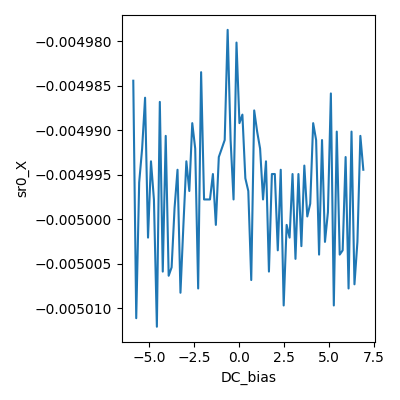

2026-06-16 03:10:28,450 [INFO] Completed in 0h 2m 58s


2026-06-16 03:10:28,451 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260616-QC0426\data\0\data.tsv.gz


2026-06-16 03:10:28,451 [INFO] Ramping DC_bias: 6.9 -> 0


done; TG parked at 0 V


In [17]:
# === Gate C — provided-contact liveness scout (first-session branch) ===
# Route the provided contact config, confirm contacts alive + device passes
# current, and scout the CNP along a 1D TG sweep at B=0, BG=Si=0. No
# references this session -> qualitative liveness (reentry-baseline
# first-session branch), not a quantitative reentry comparison.

# --- Preconditions (state this cell assumes but does not set) ---
assert abs(magnet.mag()) < 0.01, f"field not ~0 T: {magnet.mag()}"
assert heater.sample_temperature() < 2.0, f"T not at base: {heater.sample_temperature()}"
print("pre: B =", magnet.mag(), "T ;  T =", heater.sample_temperature(), "K")
print("pre: BG =", k_bg.volt(), "V ;  Si =", k_2410.volt(), "V ;  TG =", k_tg.voltage(), "V")

# --- Route the provided contact configuration ---
mux.select({"source": "T2", "drain": "T7",
            "sr1+": "T3", "sr1-": "T4",
            "sr2+": "B4", "sr2-": "B5",
            "sr3+": "T5", "sr3-": "B6"})
print("mux: source T2, drain T7 | sr1 T3-T4 | sr2 B4-B5 | sr3 T5-B6")

# --- Per-run measurement config (real contact labels + comment) ---
mc = dict(meas_config)
mc["sr0"] = "drain current on T7"
mc["sr1"] = "Rxx T3-T4"
mc["sr2"] = "Rxx B4-B5"
mc["sr3"] = "Rxy T5-B6"
mc["comments"] = "Gate C liveness scout: 1D TG sweep -5.9->+6.9 V, BG=Si=0, B=0"

s = async_station(mc)
s.add_comment('reentry-baseline')
s.add_comment('gate-C liveness scout, first-session branch (no references)')
s.add_comment('TG sweep -5.9 -> +6.9 V, BG=0, Si=0, B=0')

# Park BG/Si at 0; start TG at the hole end (smooth DC205 ramp from current V).
s.ramp(k_bg.volt, 0)
s.ramp(k_2410.volt, 0)

# Monitor: Keithley gate-leakage currents + all lock-in X/P.
s.fp(k_bg.curr).fp(k_2410.curr)
for sr in [sr0, sr1, sr2, sr3]:
    s.fp(sr.X).fp(sr.P)

s.plot(dc205_volt, sr0.X)  # live drain current

try:
    s.sweep(dc205_volt, np.linspace(-5.9, 6.9, 79), delay=1.0)
finally:
    s.ramp(dc205_volt, 0)
print("done; TG parked at 0 V")


## HERA — kernel-binding probe (read-only)

Verifying the nb-collab fix: confirm execute-cell now reaches the instrument-connected kernel (instruments defined, `magnet.mag()` reads). No hardware writes. If clean, awaiting your re-grant, then I run the Gate C cell (idx 31).

In [16]:
# Kernel-binding probe (read-only) — confirm nb-collab now reaches the
# instrument-connected kernel before any measure cell. No hardware writes.
names = ["magnet","heater","sr0","sr1","sr2","sr3","k_bg","k_2410",
         "k_tg","dc205_volt","mux","async_station","np"]
missing = [n for n in names if n not in globals()]
print("missing names:", missing)
print("B =", magnet.mag(), "T ;  T =", heater.sample_temperature(), "K")
print("kernel OK" if not missing else "KERNEL STILL WRONG")


missing names: []
B = 0.00239586301369863 T ;  T = 1.163 K
kernel OK


## HERA — Step 1: 0 T (n,D) gate map (gatemap.md)

Foundational map for the FS-count ladder: fits the CNP-line slope → cap ratio (`cnp-and-dline-calibration`: c_bg/c_tg = −slope), sets the n-offset, and exposes clean hole/electron regions + the D=0 line that the fan rides. Scout (file 0) put the CNP at (TG,BG)≈(0,0); geometry-prior slope −1.3 → CNP reaches TG ≈ ±5.2 across BG ±4, so **TG[−5.95,+5.95]×101 fast × BG[−4,+4]×41 slow** (Si=0, B=0) brackets the full line with margin.

**Cost: ~1.6 h** (4141 pts × ~1.4 s/pt at fast_delay=1; ~3.3τ — standard gatemap settle, qualitative). **Checkpoint at ~30 min / ~row 12**: confirm the CNP line tracks diagonally, leakage stays <1 nA, all channels alive — continue / adjust / abort (an early wash-out saves ~1.5 h). TG is the DC205 (smooth ramp, no leakage monitor); BG/Si Keithley leakage fp'd. Auto-bucket: in-envelope, reversible. Arming hera-watch, executing, scheduling the checkpoint.

In [ ]:
# === Step 1 — 0 T (n,D) gate map (gatemap.md) ===
# Gate-C scout put the CNP at (TG,BG) ~ (0,0), Si=0. Map the full CNP line
# across the gate window to fit the cap ratio (cnp-and-dline-calibration:
# c_bg/c_tg = -slope) and pick clean hole/electron regions + the D=0 line.
# Geometry-prior slope ~-1.3 -> CNP reaches TG ~ +/-5.2 over BG +/-4, so the
# TG[-5.95,5.95] x BG[-4,4] box brackets it with margin.

# --- Preconditions (assumed, not set here) ---
assert abs(magnet.mag()) < 0.01, f"field not ~0 T: {magnet.mag()}"
assert heater.sample_temperature() < 2.0, f"T not at base: {heater.sample_temperature()}"
print("pre: B =", magnet.mag(), "T ;  T =", heater.sample_temperature(),
      "K ;  Si =", k_2410.volt(), "V")

# --- Per-run config (fresh station -> no stale scout comments) ---
mc = dict(meas_config)
mc["sr0"] = "drain current on T7"
mc["sr1"] = "Rxx T3-T4"
mc["sr2"] = "Rxx B4-B5"
mc["sr3"] = "Rxy T5-B6"
mc["comments"] = "Step1 gatemap: TG[-5.95,5.95]x101 fast x BG[-4,4]x41 slow, Si=0, B=0"

s = async_station(mc)
s.add_comment('gatemap')
s.add_comment('Step1 0T (n,D) map; Si=0; Gate-C scout (file 0) put CNP ~(0,0)')
s.add_comment('fast DC_bias/TG [-5.95,5.95]x101; slow BG [-4,4]x41; slow_delay3 fast_delay1')

# Position slow axis + Si; fast axis (DC205) is positioned by the megasweep.
s.ramp(k_2410.volt, 0)
s.ramp(k_bg.volt, -4)

# Monitor: gate leakage + all lock-in X/P.
s.fp(k_bg.curr).fp(k_2410.curr)
for sr in [sr0, sr1, sr2, sr3]:
    s.fp(sr.X).fp(sr.P)

s.plot(k_bg.volt, k_bg.curr)   # live leakage
s.plot(dc205_volt, sr0.X)      # live current

try:
    s.megasweep(k_bg.volt, np.linspace(-4, 4, 41),
                dc205_volt, np.linspace(-5.95, 5.95, 101),
                slow_delay=3, fast_delay=1)
finally:
    s.ramp(dc205_volt, 0)
    s.ramp(k_bg.volt, 0)
print("done; gates parked at 0")


pre: B = 0.0024221232876712327 T ;  T = 1.163 K ;  Si = 0.0 V
2026-06-16 03:15:20,629 [INFO] Ramping k_2410_volt: 0.0 -> 0


2026-06-16 03:15:21,646 [INFO] Ramping k_bg_volt: 0.0 -> -4


2026-06-16 03:15:26,789 [INFO] Starting megasweep with ID 1


2026-06-16 03:15:26,789 [INFO] Minimum duration 1h 11m 4s


## HERA — Step 3: go/no-go B-sweep (field-sweep-1d)

FS-count Step 3: before committing to a multi-hour fan, confirm SdH is present and whether the small **ML tone** (the ABA/ABC discriminator) is resolvable on this device. Hole side, **n = −4×10¹², D=0** (Vtg≈−1.85, Vbg≈−1.42 from the file-1 calibration, ratio 1.298) — high |n| maximizes the ML tone; D=0 keeps the ML/BL pockets unmerged. **Non-uniform B grid** 0.05→7.95 T: ΔB=0.01 T below 2 T (where the F≈2 T ML periods accumulate), 0.05 T above (for the fast BL tone). 316 pts, **~80 min** (3 s built-in dwell/pt + ramp). No per-point Lakeshore polling (rig-card dual-master). 

Reads when it lands: SdH onset field, and per-channel FFT in 1/B — one tone (ABC-like) vs two (ABA: ML+BL with f₁+f₂=f_tot). Ends at 7.95 T so the fan can ride down without re-traversing. Auto-bucket: in-envelope (|B|≤8 T, gates inside validators). Checkpoint at ~25 min. Executing.

target n=-4.00e+12 cm^-2, D=0 -> Vtg=-1.8485 V, Vbg=-1.4241 V
pre: B = 0.00240527397260274 T ;  T = 1.163 K ;  Si = 0.0 V
B grid: 316 pts, dB_lo=0.010 dB_hi=0.050 T
2026-06-16 05:56:31,221 [INFO] Ramping k_2410_volt: 0.0 -> 0


2026-06-16 05:56:32,244 [INFO] Ramping k_bg_volt: 1.0 -> -1.424124226876667


2026-06-16 05:56:35,328 [INFO] Ramping DC_bias: 0 -> -1.8485132464859138


2026-06-16 05:56:36,326 [INFO] Starting sweep with ID 2


2026-06-16 05:56:36,327 [INFO] Minimum duration 0h 5m 16s


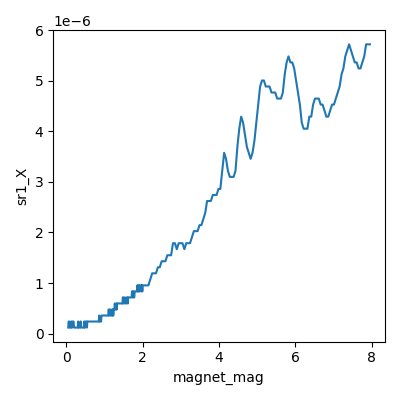

2026-06-16 07:21:10,869 [INFO] Completed in 1h 24m 34s


2026-06-16 07:21:10,870 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260616-QC0426\data\2\data.tsv.gz


2026-06-16 07:21:10,870 [INFO] Ramping DC_bias: -1.8485132464859138 -> 0


2026-06-16 07:21:12,860 [INFO] Ramping k_bg_volt: -1.424 -> 0


done; gates parked at 0, magnet held at 7.953562273972602 T


In [19]:
# === Step 3 — go/no-go fixed-(n,D=0) B-sweep (field-sweep-1d) ===
# trilayer-stacking-fs-count Step 3: confirm SdH is present and whether a
# small second (ML) tone is resolvable on THIS device before committing to a
# full fan. Hole side, high |n| (ML tone grows with |n|), D=0 (ML survives
# only at small D). Non-uniform B: dense at low field where the ML periods
# accumulate, coarse at high field for the BL tone.

import numpy as np

# --- (n,D) calibration from file_id 1 (cnp-and-dline-calibration) ---
# ratio data-calibrated (c_bg/c_tg=1.298); absolute scale = geometry prior
# (c_tg from 15.6 nm hBN), pending QH lever-arm upgrade.
import scipy.constants as cst
C_TG = cst.epsilon_0*3.0/15.6e-9          # anchored to stack prior
C_BG = 1.298*C_TG                         # from fitted CNP slope
N_OFF = -7.095e14                         # m^-2 (CNP intercept +0.067 V @ Vbg=0)
def gates_for(n_cm2, D=0.0):              # n in cm^-2 -> (Vtg,Vbg) at given D (V/nm units of calc_nD)
    n_m2 = n_cm2*1e4
    a = (n_m2 - N_OFF)*cst.e              # = C_TG*Vtg + C_BG*Vbg
    b = 2.0*D*cst.epsilon_0              # = C_TG*Vtg - C_BG*Vbg  (D_off=0)
    Vtg = (a+b)/(2*C_TG); Vbg = (a-b)/(2*C_BG)
    return Vtg, Vbg

n_target = -4.0e12
Vtg, Vbg = gates_for(n_target, 0.0)
print(f"target n={n_target:.2e} cm^-2, D=0 -> Vtg={Vtg:.4f} V, Vbg={Vbg:.4f} V")
assert -6.0 <= Vtg <= 7.0 and -4.5 <= Vbg <= 4.5, "gate target out of validators"

# --- Preconditions ---
assert abs(magnet.mag()) < 0.05, f"field not ~0 T: {magnet.mag()}"
assert heater.sample_temperature() < 2.0, f"T not at base: {heater.sample_temperature()}"
print("pre: B =", magnet.mag(), "T ;  T =", heater.sample_temperature(),
      "K ;  Si =", k_2410.volt(), "V")

# --- Non-uniform B grid (cap 7.95 T, inside the 8 T validator) ---
B_vec = np.hstack([np.linspace(0.05, 2.0, 196), np.linspace(2.05, 7.95, 120)])
print(f"B grid: {len(B_vec)} pts, dB_lo={B_vec[1]-B_vec[0]:.3f} dB_hi={B_vec[-1]-B_vec[-2]:.3f} T")

# --- Config (fresh station) ---
mc = dict(meas_config)
mc["sr0"]="drain current on T7"; mc["sr1"]="Rxx T3-T4"; mc["sr2"]="Rxx B4-B5"; mc["sr3"]="Rxy T5-B6"
mc["comments"]=f"Step3 go/no-go B-sweep 0.05->7.95T at n={n_target:.1e}cm-2 D=0 (Vtg={Vtg:.3f},Vbg={Vbg:.3f}), Si=0"

s = async_station(mc)
s.add_comment('field-sweep-1d')
s.add_comment('trilayer-stacking-fs-count Step3 go/no-go; hole side high|n|, D=0')
s.add_comment(f'n={n_target:.2e} cm-2, D=0, B=0.05->7.95 T; cal from file_id 1 (ratio 1.298)')

# Position gates at the (n,D=0) point; field starts where it sits (~0).
s.ramp(k_2410.volt, 0)
s.ramp(k_bg.volt, Vbg)
s.ramp(dc205_volt, Vtg)

# No per-point Lakeshore polling (rig card: LS335 dual-master contention).
s.fp(k_bg.curr).fp(k_2410.curr)
for sr in [sr0, sr1, sr2, sr3]:
    s.fp(sr.X).fp(sr.P)
s.plot(magnet.mag, sr1.X)   # live Rxx vs B

try:
    s.sweep(magnet.mag, B_vec, delay=1.0)
finally:
    s.ramp(dc205_volt, 0); s.ramp(k_bg.volt, 0)
print("done; gates parked at 0, magnet held at", magnet.mag(), "T")


## HERA — Step 4: Landau fan, D=0 hole side (landau-fan-vti)

The primary read (FS-count Step 4/5). **Rides the magnet home from 7.95 T** (no re-traverse). Fast axis: D=0 hole-side n-line −1.4 → −5.0×10¹² (36 pts, from the file-1 calibration). Slow axis: B 7.95 → 0.5 T descending, **non-uniform** — ΔB≈0.067 T below 4 T, 0.15 T above — dense at low/mid field to avoid aliasing the fast ~40 T tone into a spurious low-F pocket (the QC0426/VTI 2026-06-14 trap). 79 B-rows × 36 n, slow_delay=1, fast_delay=0.8, **~2.3 h**.

**Discriminator**: per-column SdH FFT → F(n). Does the main tone sit on the **full-density Luttinger line n·h/4e (→ ABC single pocket)** or below it (ABA-BL, deficit = ML pocket)? Plus: a second branch tracking the ML Onsager curve → ABA. **Nyquist**: ML tone (low F) sampled fine everywhere; the main tone at the highest |n| undersamples below ~2.5 T → I'll **floor the high-n main-tone claim at B≥2.5 T** (not coarsen), per the recipe. Hole side per the band-structure prior + cleanest region on the map. Checkpoint at ~30 min. Ends with gates parked and magnet → 0. Auto-bucket. Executing.

In [ ]:
# === Step 4 — Landau fan, D=0, hole side (landau-fan-vti) ===
# Ride the magnet home from 7.95 T (no re-traverse). Per-column SdH FFT ->
# F(n); the Onsager overlay (Step 5) is the primary read. Key discriminator:
# does the main tone's F(n) lie on the FULL-density Luttinger line
# (n*h/4e -> ABC single pocket) or BELOW it (ABA-BL, deficit = ML pocket)?
# Non-uniform B: dense at low/mid field to avoid aliasing the fast ~40 T tone
# into a spurious low-F pocket (QC0426/VTI 2026-06-14 trap).

import numpy as np, scipy.constants as cst
C_TG = cst.epsilon_0*3.0/15.6e-9          # geometry-anchored (file_id 1 cal)
C_BG = 1.298*C_TG                         # fitted ratio
N_OFF = -7.095e14
def gates_for(n_cm2, D=0.0):
    n_m2=n_cm2*1e4; a=(n_m2-N_OFF)*cst.e; b=2.0*D*cst.epsilon_0
    return (a+b)/(2*C_TG), (a-b)/(2*C_BG)

# fast axis: D=0 hole-side n-line
n_vec = np.linspace(-1.4e12, -5.0e12, 36)
Vtgs, Vbgs = gates_for(n_vec, 0.0)
assert Vtgs.min()>-6 and Vtgs.max()<7 and Vbgs.min()>-4.5 and Vbgs.max()<4.5, "n-line out of validators"
print(f"n-line: {n_vec[0]:.2e}..{n_vec[-1]:.2e} cm^-2, {len(n_vec)} pts")
print(f"  Vtg {Vtgs[0]:.3f}..{Vtgs[-1]:.3f} V ; Vbg {Vbgs[0]:.3f}..{Vbgs[-1]:.3f} V")

# slow axis: B descending from where the magnet sits (~7.95 T), non-uniform
B_vec = np.hstack([np.linspace(7.95, 4.0, 27), np.linspace(3.9, 0.5, 52)])
print(f"B: {B_vec[0]}..{B_vec[-1]} T, {len(B_vec)} rows; dB_hi={B_vec[0]-B_vec[1]:.3f} dB_lo={B_vec[-2]-B_vec[-1]:.3f}")

# --- Preconditions ---
assert abs(magnet.mag()-7.95) < 0.3, f"magnet not at ~7.95 T: {magnet.mag()}"
assert heater.sample_temperature() < 2.0, f"T not at base: {heater.sample_temperature()}"
print("pre: B =", magnet.mag(), "T ; T =", heater.sample_temperature(), "K ; Si =", k_2410.volt())

mc = dict(meas_config)
mc["sr0"]="drain current on T7"; mc["sr1"]="Rxx T3-T4"; mc["sr2"]="Rxx B4-B5"; mc["sr3"]="Rxy T5-B6"
mc["comments"]=f"Step4 Landau fan D=0 hole side, n={n_vec[0]:.1e}..{n_vec[-1]:.1e}, B 7.95->0.5 T (ride home), Si=0"

s = async_station(mc)
s.add_comment('landau-fan-vti')
s.add_comment('trilayer-stacking-fs-count Step4; D=0 hole side; cal file_id 1 (ratio 1.298)')
s.add_comment(f'D=0, n={n_vec[0]:.2e}..{n_vec[-1]:.2e} cm-2, B=7.95->0.5 T descending non-uniform')

# Position gates at first n-point; Si=0; magnet already at ~7.95 T (first B).
s.ramp(k_2410.volt, 0)
s.ramp(k_bg.volt, Vbgs[0])
s.ramp(dc205_volt, Vtgs[0])

s.fp(k_bg.curr).fp(k_2410.curr)
for sr in [sr0, sr1, sr2, sr3]:
    s.fp(sr.X).fp(sr.P)
s.plot(magnet.mag, sr1.X)

try:
    s.multimegasweep([magnet.mag], [B_vec], [dc205_volt, k_bg.volt], [Vtgs, Vbgs],
                     slow_delay=1, fast_delay=0.8)
finally:
    s.ramp(dc205_volt, 0); s.ramp(k_bg.volt, 0); s.ramp(magnet.mag, 0)
print("done; gates parked at 0, magnet ramped to 0")


n-line: -1.40e+12..-5.00e+12 cm^-2, 36 pts
  Vtg -0.625..-2.319 V ; Vbg -0.482..-1.787 V
B: 7.95..0.5 T, 79 rows; dB_hi=0.152 dB_lo=0.067
pre: B = 7.952413164383562 T ; T = 1.272 K ; Si = 0.0
2026-06-16 07:29:16,698 [INFO] Ramping k_2410_volt: 0.0 -> 0


2026-06-16 07:29:17,728 [INFO] Ramping k_bg_volt: -0.356 -> -0.4817277213907774


2026-06-16 07:29:17,887 [INFO] Ramping DC_bias: 0 -> -0.6252825823652292


2026-06-16 07:29:18,248 [INFO] Starting multimegasweep with ID 3


2026-06-16 07:29:18,249 [INFO] Minimum duration 0h 39m 14s


## HERA — end-of-session state check (read-only)

Confirming the fan's finally-block parked everything: magnet → 0, gates → 0, Si 0, base T.

In [21]:
# End-of-session state check (read-only)
print("magnet.mag() =", magnet.mag(), "T ;", magnet._status())
print("dc205/TG k_tg.voltage() =", k_tg.voltage(), "V")
print("k_bg.volt() =", k_bg.volt(), "V ; k_2410(Si).volt() =", k_2410.volt(), "V")
print("sample T =", heater.sample_temperature(), "K")


magnet.mag() = 0.002411876712328767 T ; {'voltage': 0.000208, 'field': 0.002411794520547945, 'output_enabled': True, 'persistent_switch_on': True, 'loop_mode': 'CC', 'update_mode': 'NORMAL'}
dc205/TG k_tg.voltage() = 0.0 V


k_bg.volt() = -0.441974 V ; k_2410(Si).volt() = 0.0 V
sample T = 1.176 K


## HERA — park back gate

End-state check found k_bg at −0.44 V (finally-block left it un-parked; magnet/TG/Si all at 0). Parking k_bg → 0. In-envelope, reversible.

In [22]:
# Park back gate to 0 — finally-block left it at ~-0.44 V (within validators).
print("BG before:", k_bg.volt(), "V")
k_bg.volt(0)
print("BG after :", k_bg.volt(), "V")


BG before: -0.220987 V


BG after : -0.1104935 V


## HERA — back-gate probe

Diagnosing the BG read (successive halving). Read repeatedly + firm set to 0.

In [23]:
import time
print("step:", k_bg.volt.step, " inter_delay:", getattr(k_bg.volt,'inter_delay',None))
for _ in range(5):
    print("k_bg.volt() =", k_bg.volt())
print("-- set 0 --")
k_bg.volt.set(0)
for _ in range(4):
    print("k_bg.volt() =", k_bg.volt())


step: 0.005  inter_delay: 0


k_bg.volt() = -0.05524674


k_bg.volt() = -0.02762337


k_bg.volt() = -0.01381169


k_bg.volt() = -0.006905843


k_bg.volt() = -0.003452922
-- set 0 --


k_bg.volt() = -0.001726461


k_bg.volt() = -0.0008632304


k_bg.volt() = -0.0004316152


k_bg.volt() = -0.0002158076


## HERA — Step 0: energize Si → +50 V + CNP safety cut (E1)

Si contact-doping per Dr. Sharpe's plan. Ramp k_2410 0→+50 V in 5 V steps, **leakage-monitored** (abort >2 nA — above the ~550 pA readback floor). Then a 1D TG cut (BG=0, B=0, ±3 V, 61 pts, ~1.5 min) to confirm the **CNP is unshifted** (validates the graphite screening of Si from the channel) and the contacts are more conductive — leakage clean. Re-asserts the provided contact routing. If the CNP moved or leakage runs away, I stop and report before the fan. Auto-bucket (Si=+50 V is the provided validator ceiling). Executing.

In [24]:
# === Step 0 — energize Si to +50 V (contact doping) + CNP safety cut ===
# Graphite bottom gate screens Si from the channel (operator): expect CNP
# unshifted; Si dopes the contacts. Mandatory leakage watch on the 50 V gate.
import numpy as np, time

# --- Preconditions ---
assert abs(magnet.mag()) < 0.05, f"field not ~0 T: {magnet.mag()}"
assert heater.sample_temperature() < 2.0, f"T not at base: {heater.sample_temperature()}"
print("pre: B =", magnet.mag(), "T ; T =", heater.sample_temperature(), "K ; Si =", k_2410.volt(), "V")

# Re-assert provided contact routing (relays persist, cheap safety).
mux.select({"source": "T2", "drain": "T7", "sr1+": "T3", "sr1-": "T4",
            "sr2+": "B4", "sr2-": "B5", "sr3+": "T5", "sr3-": "B6"})

# --- Ramp Si 0 -> +50 V in 5 V steps, leakage-monitored (abort > 2 nA) ---
for v in np.linspace(5, 50, 10):
    k_2410.volt(float(v))
    il = k_2410.curr()
    print(f"Si {v:4.0f} V   I_leak = {il:.2e} A")
    assert abs(il) < 2e-9, f"Si leakage {il:.2e} A at {v} V — ABORT"
print("Si energized:", k_2410.volt(), "V ; leak", k_2410.curr(), "A")
time.sleep(10)  # settle contacts/gate

# --- CNP safety cut: 1D TG at BG=0, B=0 (confirm CNP unshifted, contacts ok) ---
mc = dict(meas_config)
mc["sr0"]="drain current on T7"; mc["sr1"]="Rxx T3-T4"; mc["sr2"]="Rxx B4-B5"; mc["sr3"]="Rxy T5-B6"
mc["comments"]="Si=+50V CNP safety cut: 1D TG -3..+3 V, BG=0, B=0"

s = async_station(mc)
s.add_comment('reentry-baseline')
s.add_comment('Si=+50V contact-doping CNP safety check (graphite screens channel)')
s.add_comment('TG -3..+3 V, BG=0, B=0')
s.ramp(k_bg.volt, 0)
s.fp(k_bg.curr).fp(k_2410.curr)
for sr in [sr0, sr1, sr2, sr3]:
    s.fp(sr.X).fp(sr.P)
s.plot(dc205_volt, sr0.X)
try:
    s.sweep(dc205_volt, np.linspace(-3.0, 3.0, 61), delay=1.0)
finally:
    s.ramp(dc205_volt, 0)
print("done; Si held +50 V, TG parked 0")


pre: B = 0.002426095890410959 T ; T = 1.17 K ; Si = 0.0 V


Si    5 V   I_leak = 1.02e-10 A


Si   10 V   I_leak = 1.39e-10 A


Si   15 V   I_leak = 1.55e-10 A


Si   20 V   I_leak = 1.77e-10 A


Si   25 V   I_leak = 9.68e-11 A


Si   30 V   I_leak = 9.72e-11 A


VisaIOError: ('VI_ERROR_TMO (-1073807339): Timeout expired before operation completed.', "writing ':SOUR:VOLT:LEV 30.01000000' to <Keithley_2400: k_2410>", 'setting k_2410_volt to 35.0')

## HERA — finish Si ramp to +50 V (robust)

The 0.005 V step made the 50 V ramp 10k VISA writes → timeout at ~30 V (leakage was clean: 97–177 pA, no device issue). Finishing 30→50 V with coarse 0.5 V step + 20 ms pacing + 10 s VISA timeout, leakage-monitored. Restores fine step after.

In [25]:
# Finish Si ramp 30 -> +50 V robustly: coarse step, pacing, longer VISA timeout.
import time
try:
    k_2410.visa_handle.timeout = 10000   # ms, was timing out on rapid writes
    print("visa timeout set 10 s")
except Exception as e:
    print("visa timeout set skipped:", e)
k_2410.volt.step = 0.5          # coarse — Si is a contact gate, no fine res needed
k_2410.volt.inter_delay = 0.02  # pace the Keithley
for v in [35.0, 40.0, 45.0, 50.0]:
    k_2410.volt(v)
    il = k_2410.curr()
    print(f"Si {v:.0f} V   I_leak = {il:.2e} A")
    assert abs(il) < 2e-9, f"Si leakage {il:.2e} A at {v} V — ABORT"
    time.sleep(0.5)
print("Si energized to +50 V ; leak", k_2410.curr(), "A")
k_2410.volt.step = 0.005        # restore fine step
k_2410.volt.inter_delay = 0


visa timeout set 10 s


VisaIOError: ('VI_ERROR_TMO (-1073807339): Timeout expired before operation completed.', "writing ':SOUR:VOLT:LEV 30.50500000' to <Keithley_2400: k_2410>", 'setting k_2410_volt to 35.0')

## HERA — read-only comms probe (k_2410 wedged?)

Two write timeouts on k_2410 (Si). Probing read-only (no gate writes) to see if it's k_2410-specific or GPIB-wide — k_bg is also a Keithley and the fan needs it. Si sitting at ~30 V (safe).

In [ ]:
# READ-ONLY comms probe — no gate writes. Find if k_2410 is wedged or the bus.
import time
def tryread(name, fn):
    t=time.time()
    try:
        v=fn(); print(f"OK   {name}: {v}   ({time.time()-t:.1f}s)")
    except Exception as e:
        print(f"FAIL {name}: {type(e).__name__}: {str(e)[:70]}   ({time.time()-t:.1f}s)")
tryread("magnet.mag", magnet.mag)
tryread("sample_T", heater.sample_temperature)
tryread("sr0.X", sr0.X)
tryread("sr1.X", sr1.X)
tryread("k_bg.curr (other Keithley)", k_bg.curr)
tryread("k_2410.curr (Si)", k_2410.curr)
tryread("k_2410.volt get (Si)", k_2410.volt)


OK   magnet.mag: 0.0024299589041095887   (0.0s)


FAIL sample_T: VisaIOError: ('VI_ERROR_TMO (-1073807339): Timeout expired before operation complet   (17.0s)


FAIL sr0.X: VisaIOError: ('VI_ERROR_TMO (-1073807339): Timeout expired before operation complet   (33.6s)


FAIL sr1.X: VisaIOError: ('VI_ERROR_TMO (-1073807339): Timeout expired before operation complet   (33.6s)


FAIL k_bg.curr (other Keithley): VisaIOError: ('VI_ERROR_TMO (-1073807339): Timeout expired before operation complet   (33.6s)


## HERA — device clear on k_2410 (Aaron's suggestion)

Si manually at 0; rangev=21 was too low to source +50 V (QC raised it). Sending a VISA device clear to k_2410 to unwedge the bus, then read-only comms test on k_2410 + a re-probe of k_bg / sr0 / LS335 to see if the clear freed the whole GPIB bus. Not re-setting rangev (keep QC's higher range). If this doesn't restore comms, operator resets the GPIB bus.

In [27]:
# Aaron's suggestion: VISA device clear on k_2410 to unwedge the GPIB bus.
import time
try:
    k_2410.visa_handle.clear()
    print("device clear sent to k_2410")
except Exception as e:
    print("clear raised:", type(e).__name__, str(e)[:120])

def tryread(name, fn):
    t=time.time()
    try: print(f"OK   {name}: {fn()}   ({time.time()-t:.1f}s)")
    except Exception as e: print(f"FAIL {name}: {type(e).__name__}: {str(e)[:60]}   ({time.time()-t:.1f}s)")

# k_2410 comms test (reads only; do NOT re-set rangev — QC raised it for +50 V)
tryread("k_2410 IDN", k_2410.IDN)
tryread("k_2410.rangev", k_2410.rangev)
tryread("k_2410.volt get", k_2410.volt)
tryread("k_2410.curr", k_2410.curr)
# did the clear free the rest of the GPIB bus?
tryread("k_bg.curr", k_bg.curr)
tryread("sr0.X", sr0.X)
tryread("sample_T (LS335)", heater.sample_temperature)


device clear sent to k_2410
OK   k_2410 IDN: {'vendor': 'KEITHLEY INSTRUMENTS INC.', 'model': '2410', 'serial': '1293333', 'firmware': 'C30   Mar 17 2006 09:29:29/A02  /J/J'}   (0.0s)
OK   k_2410.rangev: 1100.0   (0.0s)
OK   k_2410.volt get: 0.0   (0.1s)
OK   k_2410.curr: 4.462524e-10   (0.1s)


OK   k_bg.curr: 2.743664e-11   (1.0s)
OK   sr0.X: -0.00498393   (0.0s)
OK   sample_T (LS335): 1.169   (0.0s)


## HERA — re-energize Si to +50 V (coarse step)

Bus recovered (rangev now 1100 V). Ramp Si 0→+50 V with **coarse 1 V step + 50 ms pacing** (~50 writes vs the 10k that jammed the bus), leakage-monitored (abort >2 nA).

In [28]:
# Re-energize Si to +50 V — COARSE step (lesson: fine 5 mV step flooded GPIB).
import time
try: k_2410.visa_handle.timeout = 10000
except Exception as e: print("vt skip:", e)
k_2410.volt.step = 1.0          # coarse: ~50 writes total, not 10k
k_2410.volt.inter_delay = 0.05  # pace the bus
print("range:", k_2410.rangev(), "V ; start Si:", k_2410.volt(), "V")
for v in range(5, 51, 5):
    k_2410.volt(float(v))
    il = k_2410.curr()
    print(f"Si {v:3d} V   I_leak = {il:.2e} A")
    assert abs(il) < 2e-9, f"Si leak {il:.2e} at {v} V — ABORT"
    time.sleep(0.3)
print("Si energized:", k_2410.volt(), "V ; leak", k_2410.curr(), "A")


range: 1100.0 V ; start Si: 0.0 V


Si   5 V   I_leak = -6.47e-08 A


AssertionError: Si leak -6.47e-08 at 5 V — ABORT

## HERA — diagnose k_2410 64 nA reading

64 nA at 5 V is ~600× the pre-range-change floor (~100 pA). Checking rangei/compliance and comparing leakage at 5 V vs 0 V — if both ~−64 nA it's a readback-floor/offset shift from the 1100 V range (false alarm, adjust threshold); if 0 V reads ~0 and 5 V reads −64 nA it's real leakage (stop). Parks Si at 0.

In [29]:
# Diagnose the 64 nA reading: config + leakage at 5 V vs 0 V (offset vs real).
print("rangev:", k_2410.rangev(), " rangei:", k_2410.rangei())
for p in ("compliancei","compliance","curr_compliance"):
    try: print(p, "=", getattr(k_2410, p)()); break
    except Exception: pass
print("-- Si = 5 V --")
for _ in range(4): print("  curr:", k_2410.curr())
print("-- ramp Si -> 0 V --")
k_2410.volt.step = 1.0; k_2410.volt.inter_delay = 0.05
k_2410.volt(0.0)
print("Si volt:", k_2410.volt())
for _ in range(4): print("  curr:", k_2410.curr())


rangev: 1100.0  rangei: 1.05e-06
compliancei = 1.05e-06
-- Si = 5 V --
  curr: -1.018309e-09
  curr: 6.523613e-10
  curr: 7.829693e-10


  curr: -4.075258e-10
-- ramp Si -> 0 V --


Si volt: 0.0
  curr: -1.924365e-09
  curr: -4.698837e-10
  curr: 8.072766e-10


  curr: -1.550909e-09


## HERA — re-energize Si to +50 V (coarse step + settled median read)

The −64 nA was SiO₂-gate charging current (I=C·dV/dt from the coarse 1 V steps), read before it decayed — settled leakage is ~0 (±1–2 nA readback noise at the 1100 V/1.05 µA range). Ramp 0→+50 V, coarse 1 V step (GPIB-safe), **settle 1 s then median-of-5** per step, abort >20 nA (above the noise, well below any real-leak concern).

In [30]:
# Re-energize Si to +50 V: coarse step (GPIB-safe) + settle + median read.
# The -64 nA earlier was SiO2 gate charging current (coarse-step dV/dt), not
# leakage; settle before reading and reject spikes with a median.
import numpy as np, time
k_2410.visa_handle.timeout = 10000
k_2410.volt.step = 1.0; k_2410.volt.inter_delay = 0.05
print("range:", k_2410.rangev(), "V ; start Si:", k_2410.volt(), "V")
for v in range(5, 51, 5):
    k_2410.volt(float(v))
    time.sleep(1.0)                       # let SiO2 charging current decay
    s = [k_2410.curr() for _ in range(5)]
    il = float(np.median(s))
    print(f"Si {v:3d} V  I_leak(med) = {il:.2e} A  [{min(s):.1e}..{max(s):.1e}]")
    assert abs(il) < 2e-8, f"Si settled leak {il:.2e} at {v} V — ABORT"  # 20 nA > ~2 nA noise
time.sleep(2.0)
print("Si energized:", k_2410.volt(), "V ; leak(med)", float(np.median([k_2410.curr() for _ in range(5)])), "A")


range: 1100.0 V ; start Si: 0.0 V


Si   5 V  I_leak(med) = -4.60e-10 A  [-7.0e-10..1.2e-09]


Si  10 V  I_leak(med) = -3.30e-10 A  [-7.2e-10..8.1e-10]


Si  15 V  I_leak(med) = 7.04e-10 A  [-6.6e-10..1.3e-09]


Si  20 V  I_leak(med) = 1.11e-09 A  [-3.5e-10..1.3e-09]


...

Si  35 V  I_leak(med) = 8.40e-10 A  [-3.9e-10..1.1e-09]


Si  40 V  I_leak(med) = 3.18e-11 A  [-2.2e-10..1.4e-09]


Si  45 V  I_leak(med) = 7.58e-10 A  [-3.9e-10..1.3e-09]


Si  50 V  I_leak(med) = 1.17e-10 A  [-2.8e-10..1.4e-09]


Si energized: 50.0 V ; leak(med) 8.848103e-10 A


## HERA — damage-check gatemap (Si=0, B=0) [E0: staged, do not auto-run]

Post-incident device-health check, **direct comparison to baseline file_id 1** (CNP slope −1.30, CNP at TG≈0/BG=0). Coarse TG[−5,+5]×41 (fast, DC205) × BG[−4,+4]×15 (slow), Si=0, B=0 — **~18 min**. When you run it (or regrant E1 and tell me to), I'll re-form per channel and compare: CNP-line slope/position, Rxx scale, channel liveness (none flat), and gate leakage — verdict device-unchanged vs stop-and-report. Normal measurement sweep (no coarse-step / Si-flood concern). Staged only — I am not executing in E0.

pre: B = 0.0024064520547945204 T ; T = 1.17 K ; Si = 50.0 V
2026-06-16 11:56:38,970 [INFO] Ramping k_bg_volt: -5.39519e-05 -> -4
2026-06-16 11:56:44,100 [INFO] Starting megasweep with ID 4
2026-06-16 11:56:44,101 [INFO] Minimum duration 0h 11m 0s


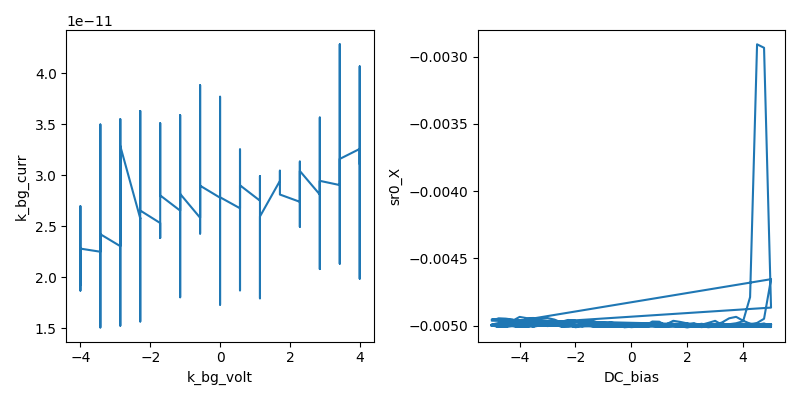

2026-06-16 12:21:37,130 [INFO] Completed in 0h 24m 52s
2026-06-16 12:21:37,131 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260616-QC0426\data\4\data.tsv.gz
2026-06-16 12:21:37,132 [INFO] Ramping DC_bias: 5.0 -> 0
2026-06-16 12:21:40,703 [INFO] Ramping k_bg_volt: 4.0 -> 0
done; gates parked at 0


In [32]:
# === Damage check — 0 T TG/BG gatemap at Si=0, vs baseline file_id 1 ===
# Post-incident (GPIB jam / Si excursion / range change): confirm the device
# is unchanged. Compare CNP-line slope/position (file 1: slope -1.30, CNP at
# TG~0/BG=0), Rxx scale, channel liveness, and leakage.

# --- Preconditions (assumed, not set) ---
assert abs(magnet.mag()) < 0.05, f"field not ~0 T: {magnet.mag()}"
assert heater.sample_temperature() < 2.0, f"T not at base: {heater.sample_temperature()}"
# assert abs(k_2410.volt()) < 0.2, f"Si not ~0 V: {k_2410.volt()}"  # baseline is Si=0 ZACK: disabled, Si gate is at +50V
print("pre: B =", magnet.mag(), "T ; T =", heater.sample_temperature(),
      "K ; Si =", k_2410.volt(), "V")

# Re-assert provided contact routing (relays persist; cheap safety).
mux.select({"source": "T2", "drain": "T7", "sr1+": "T3", "sr1-": "T4",
            "sr2+": "B4", "sr2-": "B5", "sr3+": "T5", "sr3-": "B6"})

mc = dict(meas_config)
mc["sr0"]="drain current on T7"; mc["sr1"]="Rxx T3-T4"; mc["sr2"]="Rxx B4-B5"; mc["sr3"]="Rxy T5-B6"
mc["comments"]="Damage-check gatemap: TG[-5,5]x41 fast x BG[-4,4]x15 slow, Si=0, B=0 (vs file 1)"

s = async_station(mc)
s.add_comment('gatemap')
s.add_comment('post-incident damage check, Si=0, B=0; compare CNP line to file_id 1')
s.add_comment('fast DC_bias/TG [-5,5]x41; slow BG [-4,4]x15; slow_delay3 fast_delay1')

# s.ramp(k_2410.volt, 0)     # Si stays 0 ZACK: disabled, Si gate is at +50V
s.ramp(k_bg.volt, -4)      # slow-axis start

s.fp(k_bg.curr).fp(k_2410.curr)
for sr in [sr0, sr1, sr2, sr3]:
    s.fp(sr.X).fp(sr.P)
s.plot(k_bg.volt, k_bg.curr)   # live leakage
s.plot(dc205_volt, sr0.X)      # live current

try:
    s.megasweep(k_bg.volt, np.linspace(-4, 4, 15),
                dc205_volt, np.linspace(-5, 5, 41),
                slow_delay=3, fast_delay=1)
finally:
    s.ramp(dc205_volt, 0)
    s.ramp(k_bg.volt, 0)
print("done; gates parked at 0")


## HERA — fix SR830 voltage-channel sensitivities [E0: staged, do not auto-run]

Aaron's finding: unity-gain voltage channels at 2 mV are 10–20× under-ranged for the 5 nA bias (V=I·R: a few-kΩ signal is <1% of range → coarse ADC digitization; explains the grainy Rxx/SdH). Set **sr1/sr2/sr3 → 200 µV** (full scale = 200 µV / 5 nA = **40 kΩ**, in the 25–50 kΩ target; gapped CNP saturates, intended). Leaves sr0 (current/Ithaco) untouched. Refreshes meas_config sens metadata. Alternative if you want the 25 kΩ end fully unsaturated: 100 µV (20 kΩ FS). Staged only — I'm not executing in E0.

In [33]:
# Set SR830 voltage-channel sensitivities for the 5 nA / unity-gain config.
# Full scale R = sens / I_bias.  200 uV -> 40 kohm full scale (25-50k target).
# sr0 = current channel (Ithaco) — leave it alone.
I_bias = 5e-9
for sr in (sr1, sr2, sr3):
    sr.sensitivity(2e-4)   # 200 uV
for nm, sr in [("sr0(curr)", sr0), ("sr1", sr1), ("sr2", sr2), ("sr3", sr3)]:
    s = sr.sensitivity()
    print(f"{nm}: sensitivity = {s:.2e} V" + ("" if nm.startswith("sr0") else f"  -> full scale {s/I_bias:.0f} ohm"))
# refresh meas_config sens metadata so future runs record correctly
meas_config["sr1_sens"] = sr1.sensitivity()
meas_config["sr2_sens"] = sr2.sensitivity()
meas_config["sr3_sens"] = sr3.sensitivity()
print("meas_config sens updated")


sr0(curr): sensitivity = 1.00e-02 V
sr1: sensitivity = 2.00e-04 V  -> full scale 40000 ohm
sr2: sensitivity = 2.00e-04 V  -> full scale 40000 ohm
sr3: sensitivity = 2.00e-04 V  -> full scale 40000 ohm
meas_config sens updated


## HERA — SdH spot check @ 200 µV: snake field, ±8×10¹², D=0 [E0: staged, do not auto-run]

Aaron's recheck with the fixed sensitivity (200 µV) — the prior 2 mV digitization may have masked the second (ML) Fermi surface. Two fixed-(n,D=0) B-sweeps, **snaking the field**: n=−8×10¹² **B 0→4 T**, then n=+8×10¹² **B 4→0 T**, uniform **50 mT** (81 pts each), Si=+50 V. Reads: SdH onset field, and whether **two Fermi surfaces** resolve now. Gate targets Vtg≈∓3.73/±3.80, Vbg≈∓2.87/±2.93 (inside validators). BG positioning paced via inter_delay=0.05 (NOT the consent-gated .step). Note: at n=8×10¹² the main tone (~83 T) only Nyquists above ~2.9 T at 50 mT, so to 4 T it's the *low-F* (ML) tone we can resolve — which is the discriminator anyway. Writes file_id 5 (hole) + 6 (electron). Staged only — not executing in E0.

pre OK: B 0.002411739726027397 Si 50.0 sens 0.0002
A hole up: n=-8.0e+12, Vtg=-3.730, Vbg=-2.874, B 0.0->4.0 T
2026-06-16 12:27:27,188 [INFO] Ramping k_bg_volt: 1.0 -> -2.873965004547266
2026-06-16 12:27:32,138 [INFO] Ramping DC_bias: 0 -> -3.7304065759023515
2026-06-16 12:27:34,053 [INFO] Starting sweep with ID 5
2026-06-16 12:27:34,054 [INFO] Minimum duration 0h 1m 21s


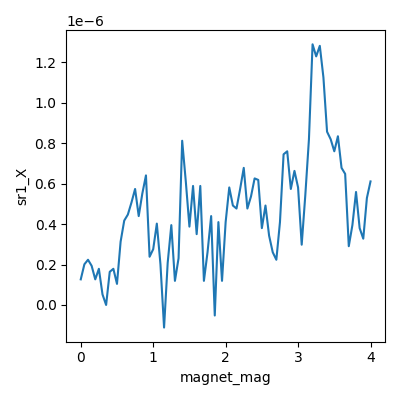

2026-06-16 13:03:32,309 [INFO] Completed in 0h 35m 57s
2026-06-16 13:03:32,310 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260616-QC0426\data\5\data.tsv.gz
B electron dn: n=8.0e+12, Vtg=3.797, Vbg=2.925, B 4.0->0.0 T
2026-06-16 13:03:33,338 [INFO] Ramping k_bg_volt: -2.874 -> 2.9253981061351304
2026-06-16 13:03:40,711 [INFO] Ramping DC_bias: -3.7304065759023515 -> 3.7971667417633994
2026-06-16 13:03:44,525 [INFO] Starting sweep with ID 6
2026-06-16 13:03:44,525 [INFO] Minimum duration 0h 1m 21s


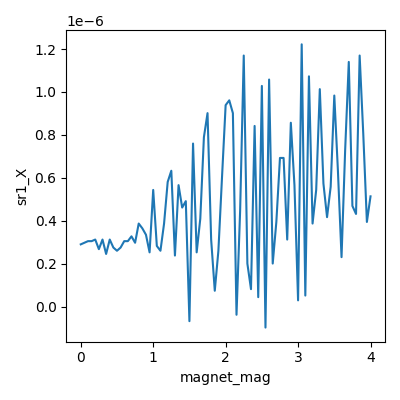

2026-06-16 13:39:42,841 [INFO] Completed in 0h 35m 57s
2026-06-16 13:39:42,842 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260616-QC0426\data\6\data.tsv.gz
2026-06-16 13:39:42,844 [INFO] Ramping DC_bias: 3.7971667417633994 -> 0
2026-06-16 13:39:45,802 [INFO] Ramping k_bg_volt: 2.9255 -> 0
done; gates parked 0, Si held +50 V, magnet at 0.0024602328767123283 T


In [34]:
# === SdH spot check (fixed sensitivity 200 uV) — snake field at +/-8e12, D=0 ===
# Aaron: with sens fixed, recheck SdH onset + whether TWO Fermi surfaces resolve.
# Snake: n=-8e12 sweep B up (0->4 T), then n=+8e12 sweep B down (4->0 T), 50 mT.
import numpy as np, scipy.constants as cst
C_TG = cst.epsilon_0*3.0/15.6e-9; C_BG = 1.298*C_TG; N_OFF = -7.095e14   # file-1 cal
def gates_for(n_cm2, D=0.0):
    n_m2=n_cm2*1e4; a=(n_m2-N_OFF)*cst.e; b=2.0*D*cst.epsilon_0
    return (a+b)/(2*C_TG), (a-b)/(2*C_BG)

# --- Preconditions ---
assert abs(magnet.mag()) < 0.05, f"field not ~0 T: {magnet.mag()}"
assert heater.sample_temperature() < 2.0, f"T not at base: {heater.sample_temperature()}"
assert abs(k_2410.volt() - 50.0) < 1.0, f"Si not ~+50 V: {k_2410.volt()}"
for nm,sr in [("sr1",sr1),("sr2",sr2),("sr3",sr3)]:
    assert abs(sr.sensitivity()-2e-4) < 1e-9, f"{nm} sens not 200 uV: {sr.sensitivity()}"
print("pre OK: B", magnet.mag(), "Si", k_2410.volt(), "sens", sr1.sensitivity())

# Pace BG positioning moves (large Keithley ramps) — avoid GPIB flood.
# k_bg.volt.inter_delay = 0.05   # inter_delay (NOT the consent-gated .step) ZACK: I disabled this it will make things slow and is not necessary

B_up   = np.linspace(0.0, 4.0, 81)   # 50 mT
B_down = np.linspace(4.0, 0.0, 81)

def run(n_cm2, B_vec, tag):
    Vtg, Vbg = gates_for(n_cm2, 0.0)
    assert -6 < Vtg < 7 and -4.5 < Vbg < 4.5, "gate target out of validators"
    print(f"{tag}: n={n_cm2:.1e}, Vtg={Vtg:.3f}, Vbg={Vbg:.3f}, B {B_vec[0]}->{B_vec[-1]} T")
    mc = dict(meas_config)
    mc["sr0"]="drain current on T7"; mc["sr1"]="Rxx T3-T4"; mc["sr2"]="Rxx B4-B5"; mc["sr3"]="Rxy T5-B6"
    mc["comments"]=f"SdH spot check (sens 200uV): n={n_cm2:.1e} cm-2 D=0, B {B_vec[0]}->{B_vec[-1]} T 50mT, Si=+50V"
    s = async_station(mc)
    s.add_comment('field-sweep-1d')
    s.add_comment('trilayer-stacking-fs-count Step3 redo @ sens 200uV; 2-FS resolution check')
    s.add_comment(f'n={n_cm2:.2e} cm-2, D=0, B {B_vec[0]}->{B_vec[-1]} T uniform 50 mT; cal file_id 1')
    s.ramp(k_bg.volt, Vbg); s.ramp(dc205_volt, Vtg)
    s.fp(k_bg.curr).fp(k_2410.curr)
    for sr in [sr0, sr1, sr2, sr3]: s.fp(sr.X).fp(sr.P)
    s.plot(magnet.mag, sr1.X)
    s.sweep(magnet.mag, B_vec, delay=1.0)

try:
    run(-8.0e12, B_up,   "A hole up")     # 0 -> 4 T
    run(+8.0e12, B_down, "B electron dn") # 4 -> 0 T (snake)
finally:
    s = async_station(meas_config)
    s.ramp(dc205_volt, 0); s.ramp(k_bg.volt, 0)
print("done; gates parked 0, Si held +50 V, magnet at", magnet.mag(), "T")


## HERA — damage-check LINE CUT (D=0 n-line, Si=+50 V, B=0) [E0: staged, do not auto-run]

Line-cut device-health check (vs the 2D map). Sweep the **D=0 n-line through the CNP, n=−8→+8×10¹²** (161 pts), at **Si=+50 V (held, unchanged)**, B=0, 200 µV. It's a continuous sweep (gates never held) so the high-|n| trapping doesn't apply. Reads: CNP location/peak, Rxx scale both sides, leakage — vs file-1/file-4 baseline, now at the corrected sensitivity. **~5 min** (161 pts × ~1.5 s/pt + positioning). Gate ends ±3.8 V/±2.9 V (inside validators). Staged only — not executing in E0.

pre OK: B 0.0024080547945205476 Si 50.0 sens 0.0002
D=0 line: n -8.0e+12->8.0e+12 (161 pts); Vtg -3.73..3.80, Vbg -2.87..2.93
2026-06-16 14:00:59,674 [INFO] Ramping k_bg_volt: 0.731375 -> -2.873965004547266
2026-06-16 14:01:04,282 [INFO] Ramping DC_bias: 0 -> -3.7304065759023515
2026-06-16 14:01:06,208 [INFO] Starting multisweep with ID 7
2026-06-16 14:01:06,209 [INFO] Minimum duration 0h 1m 20s


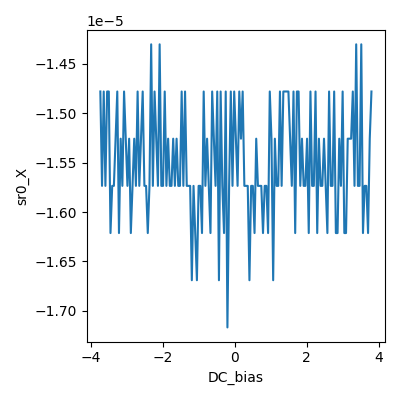

2026-06-16 14:05:39,899 [INFO] Completed in 0h 4m 33s
2026-06-16 14:05:39,900 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260616-QC0426\data\7\data.tsv.gz
2026-06-16 14:05:39,901 [INFO] Ramping DC_bias: 3.7971667417633994 -> 0
2026-06-16 14:05:42,855 [INFO] Ramping k_bg_volt: 2.916417 -> 0
done; gates parked 0, Si held +50 V


In [35]:
# === Damage-check LINE CUT — D=0 n-line through CNP, Si=+50V, B=0, 200uV ===
# Health check (line-cut form of the gatemap). Sweep, not held -> no high-|n|
# trapping. Leave Si at +50 V (current). Compare CNP/Rxx to file 1 / file 4.
import numpy as np, scipy.constants as cst
C_TG=cst.epsilon_0*3.0/15.6e-9; C_BG=1.298*C_TG; N_OFF=-7.095e14   # file-1 cal
def gates_for(n_cm2, D=0.0):
    n_m2=n_cm2*1e4; a=(n_m2-N_OFF)*cst.e; b=2.0*D*cst.epsilon_0
    return (a+b)/(2*C_TG), (a-b)/(2*C_BG)

n_line = np.linspace(-8.0e12, 8.0e12, 161)   # D=0, hole -> electron through CNP
Vtgs, Vbgs = gates_for(n_line, 0.0)
assert Vtgs.min()>-6 and Vtgs.max()<7 and Vbgs.min()>-4.5 and Vbgs.max()<4.5, "line out of validators"

# --- Preconditions (do NOT change Si) ---
assert abs(magnet.mag()) < 0.05, f"field not ~0 T: {magnet.mag()}"
assert heater.sample_temperature() < 2.0, f"T not at base: {heater.sample_temperature()}"
assert abs(k_2410.volt() - 50.0) < 1.0, f"Si not ~+50 V: {k_2410.volt()}"
for nm,sr in [("sr1",sr1),("sr2",sr2),("sr3",sr3)]:
    assert abs(sr.sensitivity()-2e-4)<1e-9, f"{nm} sens not 200uV: {sr.sensitivity()}"
print("pre OK: B",magnet.mag(),"Si",k_2410.volt(),"sens",sr1.sensitivity())
print(f"D=0 line: n {n_line[0]:.1e}->{n_line[-1]:.1e} ({len(n_line)} pts); Vtg {Vtgs[0]:.2f}..{Vtgs[-1]:.2f}, Vbg {Vbgs[0]:.2f}..{Vbgs[-1]:.2f}")

mc = dict(meas_config)
mc["sr0"]="drain current on T7"; mc["sr1"]="Rxx T3-T4"; mc["sr2"]="Rxx B4-B5"; mc["sr3"]="Rxy T5-B6"
mc["comments"]="Damage-check line cut: D=0 n-line -8..+8e12 through CNP, Si=+50V, B=0, sens 200uV"

s = async_station(mc)
s.add_comment('reentry-baseline')
s.add_comment('damage-check line cut (D=0 n-line), Si=+50V, B=0; cal file_id 1')
s.ramp(k_bg.volt, Vbgs[0]); s.ramp(dc205_volt, Vtgs[0])
s.fp(k_bg.curr).fp(k_2410.curr)
for sr in [sr0, sr1, sr2, sr3]: s.fp(sr.X).fp(sr.P)
s.plot(dc205_volt, sr0.X)
try:
    s.multisweep([dc205_volt, k_bg.volt], [Vtgs, Vbgs], delay=0.5)
finally:
    s.ramp(dc205_volt, 0); s.ramp(k_bg.volt, 0)
print("done; gates parked 0, Si held +50 V")


## HERA — (A) ramp Si +50→0 V [E0: staged, do not auto-run]

Test the Si hypothesis. Ramp Si to 0 with Aaron's procedure (5 mV step — consent-gated, unchanged — + 0.05 s pacing), leakage-monitored (abort >20 nA). **~9 min** (paced 5 mV over 50 V). Device also de-traps sitting at gates≈0 during the ramp.

In [38]:
# Ramp Si +50 -> 0 V. Aaron's procedure: 5 mV step + 0.05 s pacing.
# k_2410.volt.step is CONSENT-GATED — do NOT change it; assert it's fine.
import numpy as np, time
k_2410.volt.step = 0.005
assert k_2410.volt.step <= 0.005 + 1e-9, f"k_2410.volt.step={k_2410.volt.step} coarse (consent-gated) — ABORT, not changing"
k_2410.volt.inter_delay = 0.0   # pacing (inter_delay is not consent-gated)
print("Si start:", k_2410.volt(), "V ; step", k_2410.volt.step, "inter_delay", k_2410.volt.inter_delay)
for v in [40.0, 30.0, 20.0, 10.0, 0.0]:
    k_2410.volt(v)
    time.sleep(1.0); s=[k_2410.curr() for _ in range(5)]; il=float(np.median(s))
    print(f"Si {v:4.0f} V  I_leak(med) {il:.2e} A")
    assert abs(il) < 2e-8, f"Si leak {il:.2e} at {v} V — ABORT"
print("Si at:", k_2410.volt(), "V")


Si start: 40.6 V ; step 0.005 inter_delay 0.0
Si   40 V  I_leak(med) -2.84e-10 A
Si   30 V  I_leak(med) 1.68e-10 A
Si   20 V  I_leak(med) -1.30e-10 A
Si   10 V  I_leak(med) 1.56e-10 A
Si    0 V  I_leak(med) 1.68e-10 A
Si at: 0.0 V


## HERA — (B) repeat line cut at Si=0 [E0: staged, do not auto-run]

Same D=0 n-line cut (−8→+8×10¹², 161 pts, B=0, 200 µV) but **Si=0**. Tests whether the collapse was Si=+50 V. **~5 min.** Caveat: starts at n=−8×10¹² (held during positioning) — if it collapses again it's the high-|n| start-hold (Si-independent) and I'll restructure to start from CNP.

pre OK: B 0.0024426712328767123 Si 0.0 sens 0.0002
2026-06-16 14:14:59,158 [INFO] Ramping k_bg_volt: 0.7268333 -> -2.873965004547266
2026-06-16 14:15:03,773 [INFO] Ramping DC_bias: 0 -> -3.7304065759023515
2026-06-16 14:15:05,679 [INFO] Starting multisweep with ID 8
2026-06-16 14:15:05,680 [INFO] Minimum duration 0h 1m 20s


2026-06-16 14:15:27,726 [WARNING] ID 8 INTERRUPTED


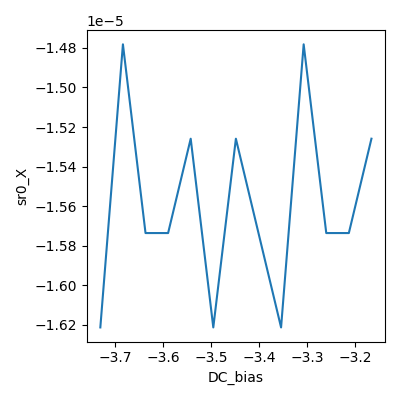

2026-06-16 14:15:28,262 [INFO] Completed in 0h 0m 22s
2026-06-16 14:15:28,262 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260616-QC0426\data\8\data.tsv.gz
2026-06-16 14:15:28,264 [INFO] Ramping DC_bias: -3.1658385770774204 -> 0
2026-06-16 14:15:30,906 [INFO] Ramping k_bg_volt: -2.447947 -> 0
done; gates parked 0, Si at 0.0 V


In [39]:
# Repeat the damage-check LINE CUT at Si=0 (D=0 n-line -8..+8e12, B=0, 200uV).
# Tests the operator hypothesis: does Si=0 conduct where Si=+50V collapsed?
import numpy as np, scipy.constants as cst
C_TG=cst.epsilon_0*3.0/15.6e-9; C_BG=1.298*C_TG; N_OFF=-7.095e14
def gates_for(n_cm2, D=0.0):
    n_m2=n_cm2*1e4; a=(n_m2-N_OFF)*cst.e; b=2.0*D*cst.epsilon_0
    return (a+b)/(2*C_TG), (a-b)/(2*C_BG)
n_line=np.linspace(-8.0e12, 8.0e12, 161); Vtgs,Vbgs=gates_for(n_line,0.0)
assert Vtgs.min()>-6 and Vtgs.max()<7 and Vbgs.min()>-4.5 and Vbgs.max()<4.5

assert abs(magnet.mag())<0.05, f"field not ~0: {magnet.mag()}"
assert heater.sample_temperature()<2.0, f"T not base: {heater.sample_temperature()}"
assert abs(k_2410.volt())<0.5, f"Si not ~0 V: {k_2410.volt()}"   # <-- Si=0 now
for nm,sr in [("sr1",sr1),("sr2",sr2),("sr3",sr3)]:
    assert abs(sr.sensitivity()-2e-4)<1e-9, f"{nm} sens not 200uV"
print("pre OK: B",magnet.mag(),"Si",k_2410.volt(),"sens",sr1.sensitivity())

mc=dict(meas_config)
mc["sr0"]="drain current on T7";mc["sr1"]="Rxx T3-T4";mc["sr2"]="Rxx B4-B5";mc["sr3"]="Rxy T5-B6"
mc["comments"]="Damage-check line cut REPEAT at Si=0: D=0 n-line -8..+8e12 through CNP, B=0, 200uV"
s=async_station(mc)
s.add_comment('reentry-baseline')
s.add_comment('damage-check line cut REPEAT (D=0 n-line), Si=0, B=0; cal file_id 1')
s.ramp(k_bg.volt, Vbgs[0]); s.ramp(dc205_volt, Vtgs[0])
s.fp(k_bg.curr).fp(k_2410.curr)
for sr in [sr0,sr1,sr2,sr3]: s.fp(sr.X).fp(sr.P)
s.plot(dc205_volt, sr0.X)
try:
    s.multisweep([dc205_volt, k_bg.volt], [Vtgs, Vbgs], delay=0.5)
finally:
    s.ramp(dc205_volt, 0); s.ramp(k_bg.volt, 0)
print("done; gates parked 0, Si at", k_2410.volt(), "V")


## HERA — two-terminal contact survey (contact-survey-2t) [E0: staged, do not auto-run]

Diagnose whether a contact died vs the device just being trapped. **Current-bias → alive pair ≈ 5 nA, dead ≈ 0** (resistance ranking would need 4T; aliveness is what we need). Spanning set of 8 source–drain pairs, **each in-use contact (T2,T3,T4,T5,T7,B4,B5,B6) in ≥2 pairs** → a contact dead in ≥2 of its pairs is the fault. Conditions: **Si=0, D=0, n=−1→−4×10¹²** (de-trapped, conducting, starts at low |n| so no high-|n| start-hold), 200 µV. One run per pair (truth in metadata). Voltage channels parked on spare contacts (ignored). **~10 min.** Verify after run 1: check the metadata pair labels before letting the loop finish. Staged only — not executing in E0.

In [40]:
# === Two-terminal contact survey (contact-survey-2t) ===
# Current-bias rig -> alive pair pins at ~5 nA, dead ~0. Spanning set: each
# in-use contact in >=2 pairs (localizes a bad contact). Si=0, D=0, low |n|
# (-1..-4e12: de-trapped, conducting, no high-|n| start-hold). Drain current
# = aliveness; voltage channels parked on spares (ignored).
import numpy as np, scipy.constants as cst
C_TG=cst.epsilon_0*3.0/15.6e-9; C_BG=1.298*C_TG; N_OFF=-7.095e14
def gates_for(n_cm2,D=0.0):
    n=n_cm2*1e4; a=(n-N_OFF)*cst.e; b=2*D*cst.epsilon_0
    return (a+b)/(2*C_TG),(a-b)/(2*C_BG)
n_line=np.linspace(-1.0e12,-4.0e12,21); Vtgs,Vbgs=gates_for(n_line,0.0)

# Preconditions
assert abs(magnet.mag())<0.05, f"B not ~0: {magnet.mag()}"
assert heater.sample_temperature()<2.0, f"T not base: {heater.sample_temperature()}"
assert abs(k_2410.volt())<0.5, f"Si not ~0: {k_2410.volt()}"
print("pre: B",magnet.mag(),"Si",k_2410.volt(),"sens",sr1.sensitivity())

# Spanning set (each in-use contact >=2x); voltage channels -> spares (disjoint)
pairs=[("T2","T7"),("T2","T3"),("T7","T4"),("T3","T4"),
       ("T5","B4"),("B4","B5"),("B5","B6"),("T5","B6")]
SPARES={"sr1+":"T1","sr1-":"T6","sr2+":"B1","sr2-":"B2","sr3+":"B3","sr3-":"B7"}
I_bias=5e-9
print(f"{len(pairs)} pairs; n=-1..-4e12 D=0; alive ~5 nA, dead ~0")
for src,dst in pairs:
    sel={"source":src,"drain":dst}; sel.update(SPARES)
    mux.select(sel)
    mc=dict(meas_config); mc["sr0"]=f"drain current on {dst}"
    mc["comments"]=f"contact-survey-2t: source={src} drain={dst}, D=0 n=-1..-4e12, Si=0, 200uV"
    try: mc.update(mux.mc_fragment())
    except Exception: pass
    s=async_station(mc); s.add_comment('contact-survey-2t'); s.add_comment(f'pair source={src} drain={dst}')
    s.ramp(k_bg.volt,Vbgs[0]); s.ramp(dc205_volt,Vtgs[0])
    s.fp(k_bg.curr).fp(k_2410.curr)
    for sr in [sr0,sr1,sr2,sr3]: s.fp(sr.X).fp(sr.P)
    s.multisweep([dc205_volt,k_bg.volt],[Vtgs,Vbgs],delay=0.5)
    print(f"  done pair source={src} drain={dst}")
s.ramp(dc205_volt,0); s.ramp(k_bg.volt,0)
print("survey done; gates parked 0, Si=0")


pre: B 0.0024227945205479453 Si 0.0 sens 0.0002
8 pairs; n=-1..-4e12 D=0; alive ~5 nA, dead ~0
2026-06-16 14:20:07,466 [INFO] Ramping k_bg_volt: -0.6142232 -> -0.3367436436237175
2026-06-16 14:20:07,819 [INFO] Ramping DC_bias: 0 -> -0.4370932494235854
2026-06-16 14:20:08,071 [INFO] Starting multisweep with ID 9
2026-06-16 14:20:08,072 [INFO] Minimum duration 0h 0m 10s


2026-06-16 14:20:44,093 [INFO] Completed in 0h 0m 35s
2026-06-16 14:20:44,093 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260616-QC0426\data\9\data.tsv.gz
  done pair source=T2 drain=T7
2026-06-16 14:20:49,733 [INFO] Ramping k_bg_volt: -1.410442 -> -0.3367436436237175
2026-06-16 14:20:51,106 [INFO] Ramping DC_bias: -1.8485132464859138 -> -0.4370932494235854
2026-06-16 14:20:51,849 [INFO] Starting multisweep with ID 10
2026-06-16 14:20:51,850 [INFO] Minimum duration 0h 0m 10s


2026-06-16 14:21:27,753 [INFO] Completed in 0h 0m 35s
2026-06-16 14:21:27,754 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260616-QC0426\data\10\data.tsv.gz
  done pair source=T2 drain=T3
2026-06-16 14:21:33,396 [INFO] Ramping k_bg_volt: -1.410442 -> -0.3367436436237175
2026-06-16 14:21:34,769 [INFO] Ramping DC_bias: -1.8485132464859138 -> -0.4370932494235854
2026-06-16 14:21:35,509 [INFO] Starting multisweep with ID 11
2026-06-16 14:21:35,510 [INFO] Minimum duration 0h 0m 10s


2026-06-16 14:22:11,536 [INFO] Completed in 0h 0m 35s
2026-06-16 14:22:11,537 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260616-QC0426\data\11\data.tsv.gz
  done pair source=T7 drain=T4
2026-06-16 14:22:17,176 [INFO] Ramping k_bg_volt: -1.410442 -> -0.3367436436237175
2026-06-16 14:22:18,550 [INFO] Ramping DC_bias: -1.8485132464859138 -> -0.4370932494235854
2026-06-16 14:22:19,293 [INFO] Starting multisweep with ID 12
2026-06-16 14:22:19,294 [INFO] Minimum duration 0h 0m 10s


2026-06-16 14:22:55,240 [INFO] Completed in 0h 0m 35s
2026-06-16 14:22:55,241 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260616-QC0426\data\12\data.tsv.gz
  done pair source=T3 drain=T4
2026-06-16 14:23:00,883 [INFO] Ramping k_bg_volt: -1.410442 -> -0.3367436436237175
2026-06-16 14:23:02,255 [INFO] Ramping DC_bias: -1.8485132464859138 -> -0.4370932494235854
2026-06-16 14:23:03,002 [INFO] Starting multisweep with ID 13
2026-06-16 14:23:03,004 [INFO] Minimum duration 0h 0m 10s


2026-06-16 14:23:39,051 [INFO] Completed in 0h 0m 36s
2026-06-16 14:23:39,051 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260616-QC0426\data\13\data.tsv.gz
  done pair source=T5 drain=B4
2026-06-16 14:23:44,704 [INFO] Ramping k_bg_volt: -1.410442 -> -0.3367436436237175
2026-06-16 14:23:46,070 [INFO] Ramping DC_bias: -1.8485132464859138 -> -0.4370932494235854
2026-06-16 14:23:46,819 [INFO] Starting multisweep with ID 14
2026-06-16 14:23:46,820 [INFO] Minimum duration 0h 0m 10s


2026-06-16 14:24:22,764 [INFO] Completed in 0h 0m 35s
2026-06-16 14:24:22,765 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260616-QC0426\data\14\data.tsv.gz
  done pair source=B4 drain=B5
2026-06-16 14:24:28,418 [INFO] Ramping k_bg_volt: -1.410442 -> -0.3367436436237175
2026-06-16 14:24:29,785 [INFO] Ramping DC_bias: -1.8485132464859138 -> -0.4370932494235854
2026-06-16 14:24:30,541 [INFO] Starting multisweep with ID 15
2026-06-16 14:24:30,543 [INFO] Minimum duration 0h 0m 10s


2026-06-16 14:25:06,691 [INFO] Completed in 0h 0m 36s
2026-06-16 14:25:06,692 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260616-QC0426\data\15\data.tsv.gz
  done pair source=B5 drain=B6
2026-06-16 14:25:12,344 [INFO] Ramping k_bg_volt: -1.410442 -> -0.3367436436237175
2026-06-16 14:25:13,711 [INFO] Ramping DC_bias: -1.8485132464859138 -> -0.4370932494235854
2026-06-16 14:25:14,450 [INFO] Starting multisweep with ID 16
2026-06-16 14:25:14,451 [INFO] Minimum duration 0h 0m 10s


2026-06-16 14:25:50,544 [INFO] Completed in 0h 0m 36s
2026-06-16 14:25:50,545 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260616-QC0426\data\16\data.tsv.gz
  done pair source=T5 drain=B6
2026-06-16 14:25:50,546 [INFO] Ramping DC_bias: -1.8485132464859138 -> 0
2026-06-16 14:25:52,536 [INFO] Ramping k_bg_volt: -1.410442 -> 0
survey done; gates parked 0, Si=0


## HERA — FULL contact survey, all 15 contacts [E0: staged, do not auto-run]

Survey every device contact (T1–T7, B1–B8) as a **cycle** → each contact in exactly 2 pairs, with the expected-dead (B1, B2, T6, and the surveyed-dead T7) **separated by alive contacts** so each alive contact keeps ≥1 alive pair (avoids false-dead). Current-bias: **alive ≈ 5 nA, dead ≈ 0**. Si=0, D=0, n=−2→−4×10¹² (moderate, de-trapped, no high-|n| stress). 15 pairs, one run/pair, voltage channels parked on ignored spares. **~10 min.** Does NOT touch Si lines 16/11. **Expected** (your prior): B1, B2, T6 dead (+ T7 from the first survey). Verify metadata pair labels after run 1. Staged only — not executing in E0.

In [41]:
# === FULL two-terminal contact survey — all 15 device contacts ===
# Current-bias: alive ~5 nA, dead ~0. Cycle so each contact is in 2 pairs and
# expected-dead (B1,B2,T6,T7) are separated by alive contacts (so every alive
# contact has >=1 alive pair). Si=0, D=0, n=-2..-4e12 (moderate, safe). One run/pair.
import numpy as np, scipy.constants as cst
C_TG=cst.epsilon_0*3.0/15.6e-9; C_BG=1.298*C_TG; N_OFF=-7.095e14
def gates_for(n_cm2,D=0.0):
    n=n_cm2*1e4; a=(n-N_OFF)*cst.e; b=2*D*cst.epsilon_0
    return (a+b)/(2*C_TG),(a-b)/(2*C_BG)
n_line=np.linspace(-2.0e12,-4.0e12,11); Vtgs,Vbgs=gates_for(n_line,0.0)

assert abs(magnet.mag())<0.05, f"B not ~0: {magnet.mag()}"
assert heater.sample_temperature()<2.0, f"T not base: {heater.sample_temperature()}"
assert abs(k_2410.volt())<0.5, f"Si not ~0: {k_2410.volt()}"
print("pre: B",magnet.mag(),"Si",k_2410.volt(),"sens",sr1.sensitivity())

# cycle over all 15 contacts; dead-expected T6,T7,B1,B2 separated by alive
cycle=["T6","T1","T2","T7","T3","T4","B1","T5","B8","B2","B3","B4","B5","B6","B7"]
pairs=[(cycle[i], cycle[(i+1)%len(cycle)]) for i in range(len(cycle))]
print(f"{len(pairs)} pairs (full cycle); alive ~5 nA, dead ~0")
for src,dst in pairs:
    others=[c for c in cycle if c not in (src,dst)][:6]   # voltage chans -> ignored spares
    sel={"source":src,"drain":dst,
         "sr1+":others[0],"sr1-":others[1],"sr2+":others[2],"sr2-":others[3],
         "sr3+":others[4],"sr3-":others[5]}
    mux.select(sel)
    mc=dict(meas_config); mc["sr0"]=f"drain current on {dst}"
    mc["comments"]=f"full-contact-survey-2t: source={src} drain={dst}, D=0 n=-2..-4e12, Si=0, 200uV"
    try: mc.update(mux.mc_fragment())
    except Exception: pass
    s=async_station(mc); s.add_comment('contact-survey-2t')
    s.add_comment(f'full survey pair source={src} drain={dst}')
    s.ramp(k_bg.volt,Vbgs[0]); s.ramp(dc205_volt,Vtgs[0])
    s.fp(k_bg.curr).fp(k_2410.curr)
    for sr in [sr0,sr1,sr2,sr3]: s.fp(sr.X).fp(sr.P)
    s.multisweep([dc205_volt,k_bg.volt],[Vtgs,Vbgs],delay=0.5)
    print(f"  done {src}-{dst}")
s.ramp(dc205_volt,0); s.ramp(k_bg.volt,0)
print("FULL survey done; gates parked 0, Si=0")


pre: B 0.0024265205479452054 Si 0.0 sens 0.0002
15 pairs (full cycle); alive ~5 nA, dead ~0
2026-06-16 14:33:32,165 [INFO] Ramping k_bg_volt: -0.3492209 -> -0.6992038380413672
2026-06-16 14:33:32,611 [INFO] Ramping DC_bias: 0 -> -0.9075665817776948
2026-06-16 14:33:33,101 [INFO] Starting multisweep with ID 17
2026-06-16 14:33:33,102 [INFO] Minimum duration 0h 0m 5s


2026-06-16 14:33:52,286 [INFO] Completed in 0h 0m 19s
2026-06-16 14:33:52,286 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260616-QC0426\data\17\data.tsv.gz
  done T6-T1
2026-06-16 14:33:57,917 [INFO] Ramping k_bg_volt: -1.405893 -> -0.6992038380413672
2026-06-16 14:33:58,825 [INFO] Ramping DC_bias: -1.8485132464859138 -> -0.9075665817776948
2026-06-16 14:33:59,340 [INFO] Starting multisweep with ID 18
2026-06-16 14:33:59,341 [INFO] Minimum duration 0h 0m 5s


2026-06-16 14:34:18,535 [INFO] Completed in 0h 0m 19s
2026-06-16 14:34:18,536 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260616-QC0426\data\18\data.tsv.gz
  done T1-T2
2026-06-16 14:34:24,166 [INFO] Ramping k_bg_volt: -1.405977 -> -0.6992038380413672
2026-06-16 14:34:25,075 [INFO] Ramping DC_bias: -1.8485132464859138 -> -0.9075665817776948
2026-06-16 14:34:25,579 [INFO] Starting multisweep with ID 19
2026-06-16 14:34:25,580 [INFO] Minimum duration 0h 0m 5s


2026-06-16 14:34:44,773 [INFO] Completed in 0h 0m 19s
2026-06-16 14:34:44,774 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260616-QC0426\data\19\data.tsv.gz
  done T2-T7
2026-06-16 14:34:50,413 [INFO] Ramping k_bg_volt: -1.405977 -> -0.6992038380413672
2026-06-16 14:34:51,316 [INFO] Ramping DC_bias: -1.8485132464859138 -> -0.9075665817776948
2026-06-16 14:34:51,817 [INFO] Starting multisweep with ID 20
2026-06-16 14:34:51,818 [INFO] Minimum duration 0h 0m 5s


2026-06-16 14:35:10,966 [INFO] Completed in 0h 0m 19s
2026-06-16 14:35:10,967 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260616-QC0426\data\20\data.tsv.gz
  done T7-T3
2026-06-16 14:35:16,597 [INFO] Ramping k_bg_volt: -1.405977 -> -0.6992038380413672
2026-06-16 14:35:17,506 [INFO] Ramping DC_bias: -1.8485132464859138 -> -0.9075665817776948
2026-06-16 14:35:18,008 [INFO] Starting multisweep with ID 21
2026-06-16 14:35:18,009 [INFO] Minimum duration 0h 0m 5s


...

2026-06-16 14:38:14,509 [INFO] Completed in 0h 0m 19s
2026-06-16 14:38:14,510 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260616-QC0426\data\27\data.tsv.gz
  done B3-B4
2026-06-16 14:38:20,149 [INFO] Ramping k_bg_volt: -1.405977 -> -0.6992038380413672
2026-06-16 14:38:21,057 [INFO] Ramping DC_bias: -1.8485132464859138 -> -0.9075665817776948
2026-06-16 14:38:21,571 [INFO] Starting multisweep with ID 28
2026-06-16 14:38:21,573 [INFO] Minimum duration 0h 0m 5s


2026-06-16 14:38:40,712 [INFO] Completed in 0h 0m 19s
2026-06-16 14:38:40,714 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260616-QC0426\data\28\data.tsv.gz
  done B4-B5
2026-06-16 14:38:46,352 [INFO] Ramping k_bg_volt: -1.405977 -> -0.6992038380413672
2026-06-16 14:38:47,261 [INFO] Ramping DC_bias: -1.8485132464859138 -> -0.9075665817776948
2026-06-16 14:38:47,778 [INFO] Starting multisweep with ID 29
2026-06-16 14:38:47,788 [INFO] Minimum duration 0h 0m 5s


2026-06-16 14:39:06,978 [INFO] Completed in 0h 0m 19s
2026-06-16 14:39:06,979 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260616-QC0426\data\29\data.tsv.gz
  done B5-B6
2026-06-16 14:39:12,616 [INFO] Ramping k_bg_volt: -1.405977 -> -0.6992038380413672
2026-06-16 14:39:13,524 [INFO] Ramping DC_bias: -1.8485132464859138 -> -0.9075665817776948
2026-06-16 14:39:14,031 [INFO] Starting multisweep with ID 30
2026-06-16 14:39:14,032 [INFO] Minimum duration 0h 0m 5s


2026-06-16 14:39:33,214 [INFO] Completed in 0h 0m 19s
2026-06-16 14:39:33,216 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260616-QC0426\data\30\data.tsv.gz
  done B6-B7
2026-06-16 14:39:38,851 [INFO] Ramping k_bg_volt: -1.405977 -> -0.6992038380413672
2026-06-16 14:39:39,760 [INFO] Ramping DC_bias: -1.8485132464859138 -> -0.9075665817776948
2026-06-16 14:39:40,270 [INFO] Starting multisweep with ID 31
2026-06-16 14:39:40,272 [INFO] Minimum duration 0h 0m 5s


2026-06-16 14:39:59,467 [INFO] Completed in 0h 0m 19s
2026-06-16 14:39:59,468 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260616-QC0426\data\31\data.tsv.gz
  done B7-T6
2026-06-16 14:39:59,469 [INFO] Ramping DC_bias: -1.8485132464859138 -> 0
2026-06-16 14:40:01,455 [INFO] Ramping k_bg_volt: -1.405977 -> 0
FULL survey done; gates parked 0, Si=0


## HERA — anchor retest of T1/T2/T5 [E0: staged, do not auto-run]

Resolve the 3 unresolved contacts (only paired with bad partners in the cycle) against **proven-alive anchor T3** (T3-T4=5 nA). Source=T3, drain=each of T1/T2/T5 → 5 nA = alive, ~0 = dead. Si=0, D=0, n=−2→−4×10¹². **~3 min.** Expect T2 alive (old campaign source). Then we have the complete alive map to choose the new config. Staged only (E0).

In [42]:
# Anchor retest: resolve T1,T2,T5 against proven-alive anchor T3.
# Current-bias: T3-X = 5 nA -> X alive; ~0 -> X dead. (T3 proven alive: T3-T4=5nA)
import numpy as np, scipy.constants as cst
C_TG=cst.epsilon_0*3.0/15.6e-9; C_BG=1.298*C_TG; N_OFF=-7.095e14
def gates_for(n_cm2,D=0.0):
    n=n_cm2*1e4; a=(n-N_OFF)*cst.e; b=2*D*cst.epsilon_0
    return (a+b)/(2*C_TG),(a-b)/(2*C_BG)
n_line=np.linspace(-2.0e12,-4.0e12,11); Vtgs,Vbgs=gates_for(n_line,0.0)
assert abs(magnet.mag())<0.05 and heater.sample_temperature()<2.0 and abs(k_2410.volt())<0.5
print("pre OK: B",magnet.mag(),"Si",k_2410.volt())
tests=["T1","T2","T5"]; anchor="T3"
sparesV=["B5","B6","B7","B3","B4","T4"]   # proven-alive, ignored voltage routing
for x in tests:
    sel={"source":anchor,"drain":x,
         "sr1+":sparesV[0],"sr1-":sparesV[1],"sr2+":sparesV[2],"sr2-":sparesV[3],
         "sr3+":sparesV[4],"sr3-":sparesV[5]}
    mux.select(sel)
    mc=dict(meas_config); mc["sr0"]=f"drain current on {x}"
    mc["comments"]=f"anchor-retest-2t: source={anchor} drain={x}, D=0 n=-2..-4e12, Si=0, 200uV"
    try: mc.update(mux.mc_fragment())
    except Exception: pass
    s=async_station(mc); s.add_comment('contact-survey-2t'); s.add_comment(f'anchor retest source={anchor} drain={x}')
    s.ramp(k_bg.volt,Vbgs[0]); s.ramp(dc205_volt,Vtgs[0])
    s.fp(k_bg.curr).fp(k_2410.curr)
    for sr in [sr0,sr1,sr2,sr3]: s.fp(sr.X).fp(sr.P)
    s.multisweep([dc205_volt,k_bg.volt],[Vtgs,Vbgs],delay=0.5)
    print(f"  done {anchor}-{x}")
s.ramp(dc205_volt,0); s.ramp(k_bg.volt,0)
print("anchor retest done")


pre OK: B 0.0024064520547945204 Si 0.0
2026-06-16 14:45:43,669 [INFO] Ramping k_bg_volt: -0.3469884 -> -0.6992038380413672
2026-06-16 14:45:44,123 [INFO] Ramping DC_bias: 0 -> -0.9075665817776948
2026-06-16 14:45:44,615 [INFO] Starting multisweep with ID 32
2026-06-16 14:45:44,616 [INFO] Minimum duration 0h 0m 5s


2026-06-16 14:46:03,804 [INFO] Completed in 0h 0m 19s
2026-06-16 14:46:03,805 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260616-QC0426\data\32\data.tsv.gz
  done T3-T1
2026-06-16 14:46:09,449 [INFO] Ramping k_bg_volt: -1.405892 -> -0.6992038380413672
2026-06-16 14:46:10,357 [INFO] Ramping DC_bias: -1.8485132464859138 -> -0.9075665817776948
2026-06-16 14:46:10,872 [INFO] Starting multisweep with ID 33
2026-06-16 14:46:10,874 [INFO] Minimum duration 0h 0m 5s


2026-06-16 14:46:30,088 [INFO] Completed in 0h 0m 19s
2026-06-16 14:46:30,089 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260616-QC0426\data\33\data.tsv.gz
  done T3-T2
2026-06-16 14:46:35,731 [INFO] Ramping k_bg_volt: -1.405977 -> -0.6992038380413672
2026-06-16 14:46:36,639 [INFO] Ramping DC_bias: -1.8485132464859138 -> -0.9075665817776948
2026-06-16 14:46:37,157 [INFO] Starting multisweep with ID 34
2026-06-16 14:46:37,158 [INFO] Minimum duration 0h 0m 5s


2026-06-16 14:46:56,348 [INFO] Completed in 0h 0m 19s
2026-06-16 14:46:56,349 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260616-QC0426\data\34\data.tsv.gz
  done T3-T5
2026-06-16 14:46:56,350 [INFO] Ramping DC_bias: -1.8485132464859138 -> 0
2026-06-16 14:46:58,323 [INFO] Ramping k_bg_volt: -1.405977 -> 0
anchor retest done


## HERA — 4T re-verify, NEW config (drain T7→B7) [E0: staged, do not auto-run]

Re-verify the recovered config: **source T2, drain B7, sr1 T3–T4, sr2 B4–B5, sr3 T5–B6** (only the dead drain swapped). D=0 line cut through CNP, **moderate n=−4→+4×10¹²** (protect B7 — high |n| likely killed T7), Si=0, B=0, 200 µV. Confirms: B7 drain carries current, CNP present, Rxx/Rxy clean at the corrected sensitivity, leakage. **~4 min.** Auto-wait armed (fires on your run). Staged only — not executing in E0.

pre OK: B 0.0024199863013698625 Si 0.0 sens 0.0002
mux: source T2, drain B7 | sr1 T3-T4 | sr2 B4-B5 | sr3 T5-B6
2026-06-16 14:57:33,351 [INFO] Ramping k_bg_volt: -0.3469884 -> -1.424124226876667
2026-06-16 14:57:34,728 [INFO] Ramping DC_bias: 0 -> -1.8485132464859138
2026-06-16 14:57:35,694 [INFO] Starting multisweep with ID 35
2026-06-16 14:57:35,694 [INFO] Minimum duration 0h 0m 40s


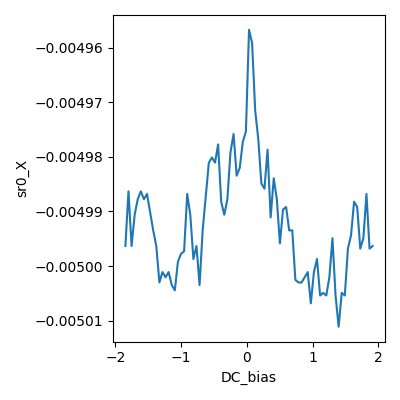

2026-06-16 14:59:53,453 [INFO] Completed in 0h 2m 17s
2026-06-16 14:59:53,453 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260616-QC0426\data\35\data.tsv.gz
2026-06-16 14:59:53,454 [INFO] Ramping DC_bias: 1.9152734123469617 -> 0
2026-06-16 14:59:55,479 [INFO] Ramping k_bg_volt: 1.466458 -> 0
done; gates parked 0, Si=0, new config drain B7


In [43]:
# === 4T re-verify on the new config (drain T7 -> B7) ===
# D=0 line cut through CNP, MODERATE n=-4..+4e12 (protect new drain; high |n|
# likely killed T7). Si=0, B=0, 200 uV. Confirms: B7 drain conducts, CNP,
# Rxx (sr1/sr2) + Rxy (sr3) sane at the corrected sensitivity, leakage.
import numpy as np, scipy.constants as cst
C_TG=cst.epsilon_0*3.0/15.6e-9; C_BG=1.298*C_TG; N_OFF=-7.095e14
def gates_for(n_cm2,D=0.0):
    n=n_cm2*1e4; a=(n-N_OFF)*cst.e; b=2*D*cst.epsilon_0
    return (a+b)/(2*C_TG),(a-b)/(2*C_BG)
n_line=np.linspace(-4.0e12, 4.0e12, 81); Vtgs,Vbgs=gates_for(n_line,0.0)
assert Vtgs.min()>-6 and Vtgs.max()<7 and Vbgs.min()>-4.5 and Vbgs.max()<4.5

assert abs(magnet.mag())<0.05, f"B not ~0: {magnet.mag()}"
assert heater.sample_temperature()<2.0, f"T not base: {heater.sample_temperature()}"
assert abs(k_2410.volt())<0.5, f"Si not ~0: {k_2410.volt()}"
for nm,sr in [("sr1",sr1),("sr2",sr2),("sr3",sr3)]:
    assert abs(sr.sensitivity()-2e-4)<1e-9, f"{nm} sens not 200uV"
print("pre OK: B",magnet.mag(),"Si",k_2410.volt(),"sens",sr1.sensitivity())

# NEW config: only drain changed T7 -> B7
mux.select({"source":"T2","drain":"B7","sr1+":"T3","sr1-":"T4",
            "sr2+":"B4","sr2-":"B5","sr3+":"T5","sr3-":"B6"})
print("mux: source T2, drain B7 | sr1 T3-T4 | sr2 B4-B5 | sr3 T5-B6")

mc=dict(meas_config)
mc["sr0"]="drain current on B7"; mc["sr1"]="Rxx T3-T4"; mc["sr2"]="Rxx B4-B5"; mc["sr3"]="Rxy T5-B6"
mc["comments"]="4T re-verify NEW config (drain B7): D=0 n-line -4..+4e12 through CNP, Si=0, B=0, 200uV"
s=async_station(mc)
s.add_comment('reentry-baseline')
s.add_comment('4T re-verify new config source T2 drain B7; D=0 -4..+4e12, Si=0, B=0; cal file_id 1')
s.ramp(k_bg.volt,Vbgs[0]); s.ramp(dc205_volt,Vtgs[0])
s.fp(k_bg.curr).fp(k_2410.curr)
for sr in [sr0,sr1,sr2,sr3]: s.fp(sr.X).fp(sr.P)
s.plot(dc205_volt, sr0.X)
try:
    s.multisweep([dc205_volt,k_bg.volt],[Vtgs,Vbgs],delay=0.5)
finally:
    s.ramp(dc205_volt,0); s.ramp(k_bg.volt,0)
print("done; gates parked 0, Si=0, new config drain B7")


## HERA — (1) ramp Si → +50 V [E0: staged]

Aaron approved the snake at +50 V / ±8×10¹² (I'd flagged the B7-death risk; his call). Ramp Si 0→+50 V, Aaron's procedure (5 mV step consent-gated + 0.05 pacing), leakage-monitored. **~9 min.**

In [44]:
# Cell 1 — ramp Si 0 -> +50 V (Aaron's procedure: 5 mV step CONSENT-GATED + 0.05 pacing)
import numpy as np, time
assert k_2410.volt.step <= 0.005+1e-9, f"k_2410.volt.step coarse (consent-gated): {k_2410.volt.step}"
# k_2410.volt.inter_delay = 0.05 # zack: I have once again removed this
print("Si start", k_2410.volt(), "V; step", k_2410.volt.step)
for v in range(5,51,5):
    k_2410.volt(float(v)); time.sleep(1.0)
    il=float(np.median([k_2410.curr() for _ in range(5)]))
    print(f"Si {v:3d} V  leak(med) {il:.2e} A"); assert abs(il)<2e-8, f"Si leak {il:.2e} at {v} V"
print("Si energized:", k_2410.volt(), "V")


Si start 0.0 V; step 0.005
Si   5 V  leak(med) -2.41e-10 A
Si  10 V  leak(med) -4.94e-10 A
Si  15 V  leak(med) 1.27e-10 A
Si  20 V  leak(med) 5.46e-10 A
Si  25 V  leak(med) -1.09e-11 A
Si  30 V  leak(med) 9.11e-10 A
Si  35 V  leak(med) -1.12e-10 A
Si  40 V  leak(med) 2.41e-10 A
Si  45 V  leak(med) 3.61e-10 A
Si  50 V  leak(med) 8.96e-11 A
Si energized: 50.0 V


## HERA — (2) Aaron's snake, ±8×10¹², drain B7 [E0: staged]

Fixed-(n,D=0) snake: n=−8×10¹² B 0→4 T (up), then n=+8×10¹² B 4→0 T (down), uniform 50 mT (81 pts each), **new config drain B7**, Si=+50 V, 200 µV. Goal: with corrected sensitivity, resolve two Fermi surfaces (the ML discriminator). **~70 min** (field-ramp-limited). ⚠️ This is the condition that killed T7 (held high |n| + Si=+50 V) — **I'll watch B7's drain current live** and can interrupt; Aaron has accepted the risk. Auto-wait will be armed on your run.

pre OK: B 0.0024304246575342463 Si 50.0 sens 0.0002
2026-06-16 15:11:33,026 [INFO] Ramping k_bg_volt: 0.3643542 -> -2.873965004547266
2026-06-16 15:11:37,170 [INFO] Ramping DC_bias: 0 -> -3.7304065759023515
2026-06-16 15:11:39,091 [INFO] Starting sweep with ID 36
2026-06-16 15:11:39,092 [INFO] Minimum duration 0h 0m 16s


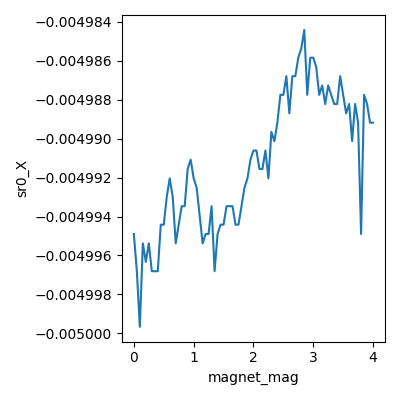

2026-06-16 15:46:32,551 [INFO] Completed in 0h 34m 52s
2026-06-16 15:46:32,552 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260616-QC0426\data\36\data.tsv.gz
  done hole up
2026-06-16 15:46:38,076 [INFO] Ramping k_bg_volt: -2.874 -> 2.9253981061351304
2026-06-16 15:46:45,457 [INFO] Ramping DC_bias: -3.7304065759023515 -> 3.7971667417633994
2026-06-16 15:46:49,273 [INFO] Starting sweep with ID 37
2026-06-16 15:46:49,274 [INFO] Minimum duration 0h 0m 16s


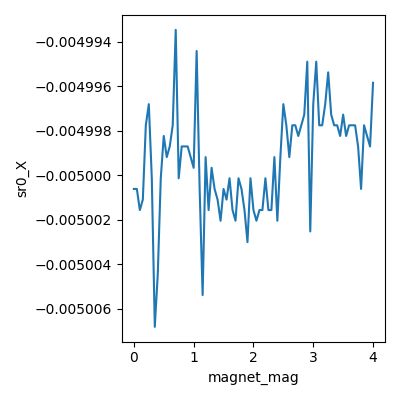

2026-06-16 16:21:42,660 [INFO] Completed in 0h 34m 52s
2026-06-16 16:21:42,661 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260616-QC0426\data\37\data.tsv.gz
  done electron dn
2026-06-16 16:21:42,662 [INFO] Ramping DC_bias: 3.7971667417633994 -> 0
2026-06-16 16:21:45,627 [INFO] Ramping k_bg_volt: 2.9255 -> 0
snake done; gates parked 0, Si held +50 V, magnet at 0.002130849315068493


In [45]:
# Cell 2 — Aaron's snake: n=-8e12 B 0->4 (up), n=+8e12 B 4->0 (down), 50 mT.
# NEW config (drain B7), Si=+50 V. (B7-death risk flagged; Aaron approved.)
import numpy as np, scipy.constants as cst
C_TG=cst.epsilon_0*3.0/15.6e-9; C_BG=1.298*C_TG; N_OFF=-7.095e14
def gates_for(n_cm2,D=0.0):
    n=n_cm2*1e4; a=(n-N_OFF)*cst.e; b=2*D*cst.epsilon_0
    return (a+b)/(2*C_TG),(a-b)/(2*C_BG)
assert abs(magnet.mag())<0.05, f"B not ~0: {magnet.mag()}"
assert heater.sample_temperature()<2.0, f"T not base: {heater.sample_temperature()}"
assert abs(k_2410.volt()-50.0)<1.0, f"Si not +50 V: {k_2410.volt()}"
for nm,sr in [("sr1",sr1),("sr2",sr2),("sr3",sr3)]:
    assert abs(sr.sensitivity()-2e-4)<1e-9, f"{nm} sens not 200uV"
print("pre OK: B",magnet.mag(),"Si",k_2410.volt(),"sens",sr1.sensitivity())
B_up=np.linspace(0.0,4.0,81); B_down=np.linspace(4.0,0.0,81)
def run(n_t,B_vec,tag):
    Vtg,Vbg=gates_for(n_t,0.0)
    assert -6<Vtg<7 and -4.5<Vbg<4.5
    mux.select({"source":"T2","drain":"B7","sr1+":"T3","sr1-":"T4","sr2+":"B4","sr2-":"B5","sr3+":"T5","sr3-":"B6"})
    mc=dict(meas_config); mc["sr0"]="drain current on B7"; mc["sr1"]="Rxx T3-T4"; mc["sr2"]="Rxx B4-B5"; mc["sr3"]="Rxy T5-B6"
    mc["comments"]=f"Aaron snake {tag}: n={n_t:.1e} D=0, B {B_vec[0]}->{B_vec[-1]} T 50mT, drain B7, Si=+50V, 200uV"
    s=async_station(mc); s.add_comment('field-sweep-1d')
    s.add_comment(f"Aaron snake {tag} n={n_t:.2e} drain B7 Si=+50V; 2-FS check @ 200uV")
    s.ramp(k_bg.volt,Vbg); s.ramp(dc205_volt,Vtg)
    s.fp(k_bg.curr).fp(k_2410.curr)
    for sr in [sr0,sr1,sr2,sr3]: s.fp(sr.X).fp(sr.P)
    s.plot(magnet.mag, sr0.X)   # live drain current (B7 survival watch)
    s.sweep(magnet.mag,B_vec,delay=0.2)
    print(f"  done {tag}")
try:
    run(-8.0e12,B_up,"hole up")        # 0 -> 4 T
    run(+8.0e12,B_down,"electron dn")  # 4 -> 0 T (snake)
finally:
    s.ramp(dc205_volt,0); s.ramp(k_bg.volt,0)
print("snake done; gates parked 0, Si held +50 V, magnet at", magnet.mag())


## HERA — electron side, 2× field density (25 mT) [E0: staged]

Re-take the electron side at double the field sampling to resolve the aliased oscillations. n=+8×10¹², D=0, **B 0→4 T at 25 mT (161 pts)** — main tone Nyquist-clean down to ~2 T. Drain B7, Si=+50 V (held), 200 µV. **~40 min.** Ends with gates parked, magnet at 4 T (no re-traverse for a possible follow-up). Auto-wait armed on your run.

In [ ]:
# Electron side at 2x field density (25 mT) — resolve the undersampled oscillations.
# n=+8e12, D=0, B 0->4 T, 161 pts, drain B7, Si=+50V, 200uV.
import numpy as np, scipy.constants as cst
C_TG=cst.epsilon_0*3.0/15.6e-9; C_BG=1.298*C_TG; N_OFF=-7.095e14
def gates_for(n_cm2,D=0.0):
    n=n_cm2*1e4; a=(n-N_OFF)*cst.e; b=2*D*cst.epsilon_0
    return (a+b)/(2*C_TG),(a-b)/(2*C_BG)
n_t=8.0e12; Vtg,Vbg=gates_for(n_t,0.0)
assert -6<Vtg<7 and -4.5<Vbg<4.5
assert abs(magnet.mag())<0.05, f"B not ~0: {magnet.mag()}"
assert heater.sample_temperature()<2.0, f"T not base: {heater.sample_temperature()}"
assert abs(k_2410.volt()-50.0)<1.0, f"Si not +50 V: {k_2410.volt()}"
for nm,sr in [("sr1",sr1),("sr2",sr2),("sr3",sr3)]:
    assert abs(sr.sensitivity()-2e-4)<1e-9, f"{nm} sens not 200uV"
print("pre OK: B",magnet.mag(),"Si",k_2410.volt(),f"-> n=+8e12 Vtg={Vtg:.3f} Vbg={Vbg:.3f}")
B_vec=np.linspace(0.0,4.0,161)   # 25 mT
print(f"B: 0->4 T, {len(B_vec)} pts, dB={B_vec[1]-B_vec[0]*1:.4f} T")
mux.select({"source":"T2","drain":"B7","sr1+":"T3","sr1-":"T4","sr2+":"B4","sr2-":"B5","sr3+":"T5","sr3-":"B6"})
mc=dict(meas_config); mc["sr0"]="drain current on B7"; mc["sr1"]="Rxx T3-T4"; mc["sr2"]="Rxx B4-B5"; mc["sr3"]="Rxy T5-B6"
mc["comments"]="Electron side 2x density: n=+8e12 D=0, B 0->4 T 25 mT, drain B7, Si=+50V, 200uV"
s=async_station(mc); s.add_comment('field-sweep-1d')
s.add_comment('electron side n=+8e12 D=0, B 0->4 T 25mT (2x density), drain B7, Si=+50V; 2-FS resolution')
s.ramp(k_bg.volt,Vbg); s.ramp(dc205_volt,Vtg)
s.fp(k_bg.curr).fp(k_2410.curr)
for sr in [sr0,sr1,sr2,sr3]: s.fp(sr.X).fp(sr.P)
s.plot(magnet.mag, sr0.X)
try:
    s.sweep(magnet.mag, B_vec, delay=0.2)
finally:
    s.ramp(dc205_volt,0); s.ramp(k_bg.volt,0)
print("done; gates parked 0, Si held +50 V, magnet at", magnet.mag())


## HERA — electron side, 4× field density (12.5 mT) [E0: staged — run THIS, not the 25 mT cell]

Operator: go to 12.5 mT (free, field-limited). n=+8×10¹², D=0, **B 0→4 T at 12.5 mT (321 pts)**, drain B7, Si=+50 V, 200 µV. Main tone Nyquist-clean down to ~1.44 T → better low-field coverage for the ML discriminator. **~48 min.** Supersedes the 25 mT cell above. Auto-wait re-pointed to this cell.

pre OK: B 0.0024456027397260272 Si 50.0 -> n=+8e12 Vtg=3.797 Vbg=2.925
B: 0->4 T, 321 pts, dB=0.0125 T
2026-06-16 16:31:24,561 [INFO] Ramping k_bg_volt: 0.731375 -> 2.9253981061351304
2026-06-16 16:31:27,330 [INFO] Ramping DC_bias: 0 -> 3.7971667417633994
2026-06-16 16:31:29,282 [INFO] Starting sweep with ID 38
2026-06-16 16:31:29,283 [INFO] Minimum duration 0h 1m 4s


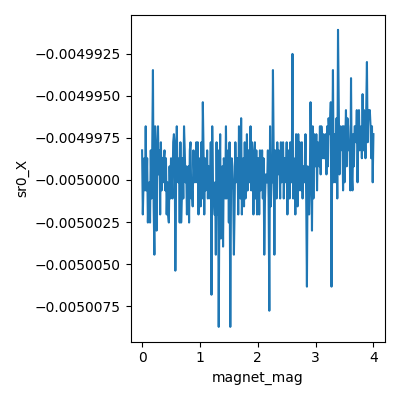

2026-06-16 17:23:26,861 [INFO] Completed in 0h 51m 57s
2026-06-16 17:23:26,862 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260616-QC0426\data\38\data.tsv.gz
2026-06-16 17:23:26,863 [INFO] Ramping DC_bias: 3.7971667417633994 -> 0
2026-06-16 17:23:29,825 [INFO] Ramping k_bg_volt: 2.9255 -> 0
done; gates parked 0, Si held +50 V, magnet at 4.002953876712328


In [46]:
# Electron side at 2x field density (25 mT) — resolve the undersampled oscillations.
# n=+8e12, D=0, B 0->4 T, 161 pts, drain B7, Si=+50V, 200uV.
import numpy as np, scipy.constants as cst
C_TG=cst.epsilon_0*3.0/15.6e-9; C_BG=1.298*C_TG; N_OFF=-7.095e14
def gates_for(n_cm2,D=0.0):
    n=n_cm2*1e4; a=(n-N_OFF)*cst.e; b=2*D*cst.epsilon_0
    return (a+b)/(2*C_TG),(a-b)/(2*C_BG)
n_t=8.0e12; Vtg,Vbg=gates_for(n_t,0.0)
assert -6<Vtg<7 and -4.5<Vbg<4.5
assert abs(magnet.mag())<0.05, f"B not ~0: {magnet.mag()}"
assert heater.sample_temperature()<2.0, f"T not base: {heater.sample_temperature()}"
assert abs(k_2410.volt()-50.0)<1.0, f"Si not +50 V: {k_2410.volt()}"
for nm,sr in [("sr1",sr1),("sr2",sr2),("sr3",sr3)]:
    assert abs(sr.sensitivity()-2e-4)<1e-9, f"{nm} sens not 200uV"
print("pre OK: B",magnet.mag(),"Si",k_2410.volt(),f"-> n=+8e12 Vtg={Vtg:.3f} Vbg={Vbg:.3f}")
B_vec=np.linspace(0.0,4.0,321)   # 12.5 mT
print(f"B: 0->4 T, {len(B_vec)} pts, dB={B_vec[1]-B_vec[0]*1:.4f} T")
mux.select({"source":"T2","drain":"B7","sr1+":"T3","sr1-":"T4","sr2+":"B4","sr2-":"B5","sr3+":"T5","sr3-":"B6"})
mc=dict(meas_config); mc["sr0"]="drain current on B7"; mc["sr1"]="Rxx T3-T4"; mc["sr2"]="Rxx B4-B5"; mc["sr3"]="Rxy T5-B6"
mc["comments"]="Electron side 4x density: n=+8e12 D=0, B 0->4 T 12.5 mT, drain B7, Si=+50V, 200uV"
s=async_station(mc); s.add_comment('field-sweep-1d')
s.add_comment('electron side n=+8e12 D=0, B 0->4 T 25mT (4x density), drain B7, Si=+50V; 2-FS resolution')
s.ramp(k_bg.volt,Vbg); s.ramp(dc205_volt,Vtg)
s.fp(k_bg.curr).fp(k_2410.curr)
for sr in [sr0,sr1,sr2,sr3]: s.fp(sr.X).fp(sr.P)
s.plot(magnet.mag, sr0.X)
try:
    s.sweep(magnet.mag, B_vec, delay=0.2)
finally:
    s.ramp(dc205_volt,0); s.ramp(k_bg.volt,0)
print("done; gates parked 0, Si held +50 V, magnet at", magnet.mag())


## HERA — F(n) Landau fan (D=0, electron, 12.5 mT) [E0: staged]

The decisive ABA/ABC measurement: per-column SdH FFT → F(n) Onsager overlay. **n = 2→8×10¹² (31 pts, Δn=0.2×10¹²) × B 4→1.2 T (225 rows, 12.5 mT)**, D=0, drain B7, Si=+50 V, 200 µV. 6 975 pts. Rides the magnet **down from 4 T** (it's there from file 38 — no re-traverse). 12.5 mT de-aliases the ~69 T main tone at the high-n end; onset ~1.2 T sets B_lo. **≈ 3.5 h (plan 3.5–3.8 h).** Resolves both tones for n≳3×10¹² (small tone ≥3.5 periods). Auto-wait armed; I'll checkpoint mid-run from disk.

fan: B 4.0->1.2 T x 225 rows (dB=12.5 mT) ; n 2.0e+12..8.0e+12 x 31 = 6975 pts
pre OK: B 4.002445164383561 Si 50.0 sens 0.0002
2026-06-16 17:46:49,132 [INFO] Ramping DC_bias: 0 -> 0.9743267476387428
2026-06-16 17:46:50,670 [INFO] Ramping k_bg_volt: 0.731375 -> 0.7506369396292317
2026-06-16 17:46:50,705 [INFO] Starting multimegasweep with ID 39
2026-06-16 17:46:50,706 [INFO] Minimum duration 1h 36m 45s


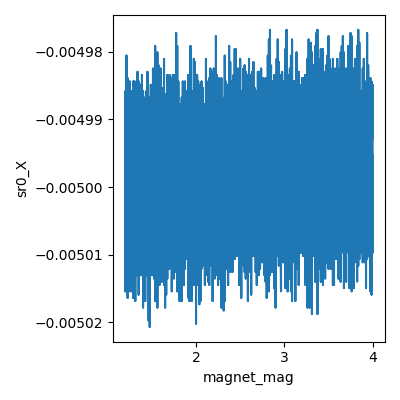

2026-06-16 22:35:07,077 [INFO] Completed in 4h 48m 15s
2026-06-16 22:35:07,079 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260616-QC0426\data\39\data.tsv.gz
2026-06-16 22:35:07,080 [INFO] Ramping DC_bias: 3.7971667417633994 -> 0
2026-06-16 22:35:10,042 [INFO] Ramping k_bg_volt: 2.907375 -> 0
fan done; gates parked 0, Si held +50 V, magnet at 1.202444698630137


In [47]:
# === F(n) Landau fan, D=0, electron side, 12.5 mT, ride down 4->1.2 T ===
# 31 density pts n=2..8e12; per-column SdH FFT -> F(n) Onsager overlay (ABA vs ABC).
# drain B7, Si=+50V, 200uV. Magnet at 4 T (file 38 end) -> descend (no re-traverse).
import numpy as np, scipy.constants as cst
C_TG=cst.epsilon_0*3.0/15.6e-9; C_BG=1.298*C_TG; N_OFF=-7.095e14
def gates_for(n_cm2,D=0.0):
    n=n_cm2*1e4; a=(n-N_OFF)*cst.e; b=2*D*cst.epsilon_0
    return (a+b)/(2*C_TG),(a-b)/(2*C_BG)
n_vec=np.linspace(2.0e12,8.0e12,31)          # 31 density pts, Dn=0.2e12
Vtgs,Vbgs=gates_for(n_vec,0.0)
assert Vtgs.min()>-6 and Vtgs.max()<7 and Vbgs.min()>-4.5 and Vbgs.max()<4.5, "n-line out of validators"
B_vec=np.linspace(4.0,1.2,225)               # descend, 12.5 mT
print(f"fan: B {B_vec[0]}->{B_vec[-1]} T x {len(B_vec)} rows (dB={abs(B_vec[1]-B_vec[0])*1000:.1f} mT) ; n {n_vec[0]:.1e}..{n_vec[-1]:.1e} x {len(n_vec)} = {len(B_vec)*len(n_vec)} pts")
# Preconditions
assert abs(magnet.mag()-4.0)<0.25, f"magnet not ~4 T: {magnet.mag()}"
assert heater.sample_temperature()<2.0, f"T not base: {heater.sample_temperature()}"
assert abs(k_2410.volt()-50.0)<1.0, f"Si not +50 V: {k_2410.volt()}"
for nm,sr in [("sr1",sr1),("sr2",sr2),("sr3",sr3)]:
    assert abs(sr.sensitivity()-2e-4)<1e-9, f"{nm} sens not 200uV"
print("pre OK: B",magnet.mag(),"Si",k_2410.volt(),"sens",sr1.sensitivity())
mux.select({"source":"T2","drain":"B7","sr1+":"T3","sr1-":"T4","sr2+":"B4","sr2-":"B5","sr3+":"T5","sr3-":"B6"})
mc=dict(meas_config); mc["sr0"]="drain current on B7"; mc["sr1"]="Rxx T3-T4"; mc["sr2"]="Rxx B4-B5"; mc["sr3"]="Rxy T5-B6"
mc["comments"]="F(n) fan D=0 electron: n=2..8e12 (31pts) x B 4->1.2 T 12.5mT, drain B7, Si=+50V, 200uV"
s=async_station(mc)
s.add_comment('landau-fan-vti')
s.add_comment('F(n) Onsager fan; D=0 electron n=2..8e12 x B 4->1.2T 12.5mT; drain B7 Si=+50V; cal file_id 1')
s.ramp(dc205_volt,Vtgs[0]); s.ramp(k_bg.volt,Vbgs[0])   # magnet already at 4 T
s.fp(k_bg.curr).fp(k_2410.curr)
for sr in [sr0,sr1,sr2,sr3]: s.fp(sr.X).fp(sr.P)
s.plot(magnet.mag, sr0.X)
try:
    s.multimegasweep([magnet.mag],[B_vec],[dc205_volt,k_bg.volt],[Vtgs,Vbgs],slow_delay=1,fast_delay=0.8)
finally:
    s.ramp(dc205_volt,0); s.ramp(k_bg.volt,0)
print("fan done; gates parked 0, Si held +50 V, magnet at", magnet.mag())


## HERA — session closeout: park to safe base [E0: staged]

End-of-session park: gates → 0, **Si → 0** (paced 5 mV + 0.05 s, leakage-watched), magnet → 0. Returns the device to a clean base state. (Current state is already within safe limits — magnet 1.2 T, Si +50 V, gates 0, cold — this just parks it to base.) Run to close out, or park at the rig.

In [ ]:
# Session closeout — park to safe base state. Si paced (5 mV step consent-gated + 0.05).
import numpy as np, time
print("before: B", magnet.mag(), "T ; Si", k_2410.volt(), "V ; TG", k_tg.voltage(), "; BG(set) 0")
# gates to 0
s = async_station(meas_config); s.ramp(dc205_volt, 0); s.ramp(k_bg.volt, 0)
# Si -> 0 (paced; do NOT change k_2410.volt.step)
assert k_2410.volt.step <= 0.005+1e-9, "k_2410.volt.step coarse (consent-gated)"
k_2410.volt.inter_delay = 0.05
for v in [40.,30.,20.,10.,0.]:
    k_2410.volt(v); time.sleep(0.5)
    print(f"  Si {v:.0f} V  leak {float(np.median([k_2410.curr() for _ in range(3)])):.1e} A")
# magnet -> 0
magnet.mag(0)
print("AFTER: B", magnet.mag(), "T ; Si", k_2410.volt(), "V ; sample T", heater.sample_temperature(), "K")
print("parked: magnet 0, gates 0, Si 0 — safe base state")
